# Polarimetry protocol: state preparation, propagation and reconstruction

This notebook follows a heralded imaging photon through a two-path interferometer, with a sample in one path. After repeated cycles, polarisation measurements at both outputs are used to reconstruct the sample’s polarisation response. We also calculate how absorption changes with the number of cycles.

The calculation uses density matrices and can describe pure or mixed input polarisation. The main reconstruction uses a Jones-matrix model that allows loss and a relative phase, although the reconstruction examples set this phase to zero. The simulated data are generated using the same model used for fitting, with no random counting noise, detector inefficiency or background counts.


## Basis and operators

We use the basis

$$
\{|1,H\rangle,\ |1,V\rangle,\ |2,H\rangle,\ |2,V\rangle\}.
$$

The first label gives the photon’s path, and the second gives its polarisation. For example, $|1,H\rangle$ means horizontal polarisation in path 1. Kronecker products follow the same order: path first, polarisation second.

The photon-pair calculation uses two polarisation labels instead. The first refers to the herald photon, and the second to the imaging photon. For example, $|H,V\rangle$ means a horizontally polarised herald photon and a vertically polarised imaging photon.

Path 1 contains the sample. Path 2 is empty and is where the input photon enters. The projectors `P1` and `P2` select path 1 and path 2, respectively. At the output, path 1 leads to ICCD0 and path 2 leads to ICCD1.

The function `dagger(A)` returns the conjugate transpose of $A$, written $A^\dagger$. To apply an operator $A$ to a density matrix $\rho$, we use

$$
\rho\mapsto A\rho A^\dagger.
$$

An identity matrix leaves its part of the state unchanged. For example, $A_{\mathrm{path}}\otimes I_{\mathrm{pol}}$ acts on the path, while $I_{\mathrm{path}}\otimes A_{\mathrm{pol}}$ acts on the polarisation.

We use the following order for the Stokes parameters and their corresponding matrices:

$$
(S_0,S_1,S_2,S_3)\ \longleftrightarrow\
(I,\sigma_z,\sigma_x,\sigma_y).
$$

Here, $S_0$ gives the total intensity. The other parameters describe the intensity differences between H/V, D/A and R/L, respectively. We use the notebook’s convention for labelling the circular states R and L, and keep this order when reconstructing the Mueller and Choi matrices.


In [2]:
import numpy as np
import matplotlib.pyplot as plt

def dagger(A):
    return A.conj().T

# Identity operator on the two-dimensional spatial/path space {|1>, |2>}
I_spat = np.eye(2, dtype=complex)

# Identity operator on the two-dimensional polarisation space
# (e.g. H/V, D/A, or R/L basis)
I_pol  = np.eye(2, dtype=complex)

# spatial projectors |1><1| and |2><2|

# Projects onto the first basis state
P1 = np.array([[1,0],[0,0]], dtype=complex)

# Projects onto the second basis state
P2 = np.array([[0,0],[0,1]], dtype=complex)

sigma_x = np.array([[0,1],[1,0]], dtype=complex)
sigma_y = np.array([[0,-1j],[1j,0]], dtype=complex)
sigma_z = np.array([[1,0],[0,-1]], dtype=complex)

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


# From a Stokes vector to a density matrix

`density_from_stokes` converts $S=(S_0,S_1,S_2,S_3)$ into a $2\times2$ polarisation density matrix using

$$
\rho=\frac12\left(S_0I+S_1\sigma_z+S_2\sigma_x+S_3\sigma_y\right)
=\frac12\begin{pmatrix}
S_0+S_1&S_2-iS_3\\
S_2+iS_3&S_0-S_1
\end{pmatrix}.
$$

The trace is $S_0$. For a normalised input photon, $S_0=1$; for an output beam or a selected detector port, $S_0$ can instead carry an intensity or probability weight.

The function rejects vectors of the wrong length, negative total intensity beyond tolerance, and Stokes vectors outside the physical region $S_1^2+S_2^2+S_3^2\leq S_0^2$. Equality describes a fully polarised state. A strict inequality allows a mixed polarisation state.

With `enforce_normalised=True`, the result is divided by its trace. This is appropriate when preparing an input state with unit probability. Use `False` when the absolute intensity is part of the quantity being studied. Normalising a detector output would discard its probability of occurrence. A zero-trace state cannot be normalised, so the function raises an error in that case.


In [3]:
def density_from_stokes(S, enforce_normalised=True, tol=1e-12):
    S = np.asarray(S, dtype=float).flatten()
    if S.size != 4:
        raise ValueError("S must be length-4: (S0,S1,S2,S3).")

    S0, S1, S2, S3 = S

    if S0 < -tol:
        raise ValueError("S0 must be >= 0.")

    if (S1**2 + S2**2 + S3**2) > (S0**2 + 1e-9):
        raise ValueError("Invalid Stokes.")

    # OPTICS convention:
    # S1 = H/V = sigma_z
    # S2 = D/A = sigma_x
    # S3 = R/L = sigma_y
    rho = 0.5 * (S0*I_pol + S1*sigma_z + S2*sigma_x + S3*sigma_y)

    if enforce_normalised:
        tr = np.trace(rho)  # for lossless case, So=Trace(rho)
        if np.abs(tr) < tol:
            raise ValueError("Trace ~ 0; cannot normalise.")
        rho = rho / tr

    return rho

## From a density matrix back to Stokes parameters

The inverse conversion takes traces against the same operator basis:

$$
S_0=\operatorname{Tr}(\rho),\quad
S_1=\operatorname{Tr}(\rho\sigma_z),\quad
S_2=\operatorname{Tr}(\rho\sigma_x),\quad
S_3=\operatorname{Tr}(\rho\sigma_y).
$$

`stokes_from_density` expects a $2\times2$ polarisation matrix. By default it first normalises the trace, so the returned vector describes the polarisation of a photon conditioned on that state, with $S_0=1$. Setting `normalise_trace=False` keeps the original probability or intensity in $S_0$.

The traces should be real for a Hermitian density matrix. Small imaginary residues arise from floating-point arithmetic; `safe_trace` returns the real part and prints a warning if the imaginary component exceeds `warn_tol`. This is a diagnostic, rather than a complete test of positivity or Hermiticity.

The implementation follows $(I,\sigma_z,\sigma_x,\sigma_y)$, despite the shorthand reference to `(I,X,Y,Z)` in its docstring. For the matrix used below, $\rho=\left(\begin{smallmatrix}a&c\\c^*&1-a\end{smallmatrix}\right)$, the resulting vector is $(1,2a-1,2\operatorname{Re}c,-2\operatorname{Im}c)$. This fixes the sign of the circular component for the rest of the notebook.


In [4]:
def stokes_from_density(rho, normalise_trace=True, tol=1e-12, warn_tol = 1e-10):
    """
    rho -> S = (S0,S1,S2,S3) using standard mapping with (I,X,Y,Z).
    If normalise_trace=True: scales rho so Tr(rho)=1 before computing.
    """
    rho = np.asarray(rho, dtype=complex)
    if rho.shape != (2,2):
        raise ValueError("rho must be 2x2.")

    tr = np.trace(rho)
    if np.abs(tr) < tol:
        raise ValueError("Trace ~ 0 (no intensity).")

    rho_use = rho / tr if normalise_trace else rho

    def safe_trace(op, label):
        val = np.trace(rho_use @ op)
        if abs(val.imag) > warn_tol:
            print(f"Warning: significant imaginary part in {label}:", val)
        return val.real

    S0 = safe_trace(I_pol, "S0")

    S1 = safe_trace(sigma_z, "S1")  # H/V
    S2 = safe_trace(sigma_x, "S2")  # D/A
    S3 = safe_trace(sigma_y, "S3")  # R/L

    return np.array([S0, S1, S2, S3], dtype=float)

# Heralding the imaging photon and selecting an output path

The photon-pair state describes **herald polarisation $\otimes$ imaging polarisation**. The state inside the interferometer describes **path $\otimes$ imaging polarisation**. 
For heralding, a polarisation projector $\Pi_h$ is applied to the first photon:

$$
\widetilde\rho_{hi}=(\Pi_h\otimes I)\rho_{hi}(\Pi_h\otimes I)^\dagger,
\qquad p_h=\operatorname{Tr}(\widetilde\rho_{hi}).
$$

`conditional_imaging_state` gives the imaging photon’s state after a chosen herald outcome. It traces out the herald photon and divides by the herald probability $p_h$ to normalise the remaining state. It returns both the imaging state and $p_h$. The later calculations assume heralding has already succeeded.

`stokes_from_4x4_density` extracts the Stokes parameters for one output path. Use `path_idx=0` for path 1 (ICCD0) and `path_idx=1` for path 2 (ICCD1). By default, it keeps $S_0$ equal to the probability of detecting the photon in that path. If the path contains no light, it returns four zeros.

In [5]:
def conditional_imaging_state(rho_pair, herald_projector):
    measurement = np.kron(herald_projector, I_pol)

    postselected = (
        measurement
        @ rho_pair
        @ dagger(measurement)
    )

    p_herald = np.trace(postselected).real

    if p_herald <= 1e-15:
        raise ValueError("Heralding outcome has zero probability.")

    # Indices:
    # herald_row, imaging_row, herald_col, imaging_col
    postselected = postselected.reshape(2, 2, 2, 2)

    # Trace out the herald photon
    rho_imaging = np.trace(
        postselected,
        axis1=0,
        axis2=2,
    )

    rho_imaging = rho_imaging / p_herald

    return rho_imaging, p_herald

def stokes_from_4x4_density(rho_4x4, path_idx, normalise_trace=False):
    """
    Extracts Stokes parameters from a 4x4 joint density matrix 
    by selecting the block corresponding to path_idx (0 or 1).
    """
    # 1. Extract the 2x2 block (d0 or d1)
    if path_idx == 0:
        rho_2x2 = rho_4x4[0:2, 0:2] # Top-left block for ICCD 0
    else:
        rho_2x2 = rho_4x4[2:4, 2:4] # Bottom-right block for ICCD 1

    # 2. Use existing Pauli math on the 2x2 block
    tr = np.trace(rho_2x2)
    
    # If intensity is zero, return zero Stokes vector
    if np.abs(tr) < 1e-15:
        return np.array([0.0, 0.0, 0.0, 0.0])

    # We usually keep normalise_trace=False to see the actual pixel intensity
    rho_use = rho_2x2 / tr if normalise_trace else rho_2x2

    S0 = np.real(np.trace(rho_use @ I_pol))
    S1 = np.real(np.trace(rho_use @ sigma_z))
    S2 = np.real(np.trace(rho_use @ sigma_x))
    S3 = np.real(np.trace(rho_use @ sigma_y))

    return np.array([S0, S1, S2, S3])

# Prepare an input state and check the conversion

We build a polarisation density matrix:

$$
\rho_{\mathrm{pol}}=\begin{pmatrix}a&c\\c^*&1-a\end{pmatrix},
$$

where $a$ is the probability of H polarisation and $c$ describes the coherence between H and V. The code checks that these values give a valid physical state.

The chosen values, $\theta=\phi=0$, give $a=1$ and $c=0$, so the photon is horizontally polarised. Here, $\theta$ describes the input state, not the sample’s orientation.

The cell converts the density matrix to Stokes parameters and back. The printed difference should be zero, apart from rounding, and the Stokes vector should be $(1,1,0,0)$.

Finally, it combines the polarisation state with `P2` to place the photon in the empty input path:

$$
\rho_{\mathrm{tot,in}}=P_2\otimes\rho_{\mathrm{pol}}.
$$

In [6]:
# imaging photon enters the inner zeno device in path 2
rho_spat_in = P2.copy()


def rho_from_ac(a, c, check=True, tol=1e-12):
    """
    Build rho = [[a, c],
                 [c*, 1-a]]
    with optional validity checks.
    """
    rho = np.array([[a, c],
                    [np.conj(c), 1 - a]], dtype=complex)
    if check:
        if not (0 - tol <= a <= 1 + tol):
            raise ValueError("a must be in [0, 1].")
        if np.abs(c)**2 > a*(1 - a) + tol:
            raise ValueError("|c|^2 must be <= a(1-a) for PSD.")
    return rho

def is_valid_ac(a, c, tol=1e-12):
    return (0 - tol <= a <= 1 + tol) and (np.abs(c)**2 <= a*(1 - a) + tol)


#horizontal light a=1, c = 0

theta = 0  # polar angle
phi = 0     # azimuthal angle
a = np.cos(theta/2)**2
c = 0.5 * np.sin(theta) * np.exp(-1j*phi)


rho = rho_from_ac(a, c)

S_in = stokes_from_density(rho)


rho_pol_in = density_from_stokes(S_in, enforce_normalised=True)

rho_tot_in = np.kron(rho_spat_in, rho_pol_in)  # 4x4

print(rho_pol_in - rho_from_ac(a, c, check=True, tol=1e-12))
S_in
#rho_tot_in 

[[0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]


array([1., 1., 0., 0.])

# Preparing H, V, D, A, R and L by heralding

We then prepare six imaging-photon polarisations in the order H, V, D, A, R, L. It starts with the photon pair in the Bell state

$$
|\Phi^+\rangle=\frac{|HH\rangle+|VV\rangle}{\sqrt2}.
$$

Measuring the herald photon prepares the imaging photon’s polarisation. Herald outcomes H, V, D and A prepare the same imaging polarisation. For circular polarisation, the labels swap: heralding L prepares R, and heralding R prepares L. This is why `desired_input_to_herald` exchanges R and L.

Here, the circular states are defined as

$$
R=\frac{(1,i)}{\sqrt2},\qquad L=\frac{(1,-i)}{\sqrt2}.
$$

Each selected herald outcome has probability $1/2$. The loop stores this probability, normalises the imaging state and places it in the empty input path using `P2`.

The six inputs are used in separate simulation runs. Their states and Stokes vectors are stored in the same order for reconstruction, and the printed results let us check each preparation.

In [7]:
# Canonical polarisation states
basis_stokes = {
    "H": np.array([1,  1,  0,  0], dtype=float),
    "V": np.array([1, -1,  0,  0], dtype=float),
    "D": np.array([1,  0,  1,  0], dtype=float),
    "A": np.array([1,  0, -1,  0], dtype=float),
    "R": np.array([1,  0,  0,  1], dtype=float),
    "L": np.array([1,  0,  0, -1], dtype=float),
}

# For |Phi+>, these herald outcomes prepare the desired imaging states.
desired_input_to_herald = {
    "H": "H",
    "V": "V",
    "D": "D",
    "A": "A",
    "R": "L",
    "L": "R",
}

# pprojectors used by the herald detector and ICCD analysers
basis_projectors = {
    label: density_from_stokes(
        S,
        enforce_normalised=True,
    )
    for label, S in basis_stokes.items()
}

# bell state |Phi+> = (|HH> + |VV>)/sqrt(2)
H = np.array([1, 0], dtype=complex)
V = np.array([0, 1], dtype=complex)

phi_plus = (
    np.kron(H, H)
    + np.kron(V, V)
) / np.sqrt(2)

rho_pair = np.outer(
    phi_plus,
    phi_plus.conj(),
)

# path 2 is the input/empty path
rho_spat_in = P2.copy()
herald_projectors = basis_projectors.copy()
iccd_analyser_projectors = basis_projectors.copy()

conditional_input_stokes = {}
herald_probabilities = {}
rho_pol_in_list = []
rho_tot_in_list = []

for input_label, herald_label in desired_input_to_herald.items():
    rho_pol_in, p_herald = conditional_imaging_state(
        rho_pair,
        herald_projectors[herald_label],
    )

    S_in = stokes_from_density(
        rho_pol_in,
        normalise_trace=True,
    )

    # we store everything using the imaging input label.
    conditional_input_stokes[input_label] = S_in
    herald_probabilities[input_label] = p_herald
    rho_pol_in_list.append(rho_pol_in)

    rho_tot_in = np.kron(
        rho_spat_in,
        rho_pol_in,
    )

    rho_tot_in_list.append(rho_tot_in)

    print(
        f"Desired imaging input {input_label}: "
        f"use herald result {herald_label}"
    )
    print("Herald probability:", p_herald)
    print("Imaging Stokes vector:", S_in)
    print("Polarization density matrix:")
    print(rho_pol_in)

    print("Total 4x4 density matrix:")
    print(rho_tot_in)
    print()
    

Desired imaging input H: use herald result H
Herald probability: 0.4999999999999999
Imaging Stokes vector: [1. 1. 0. 0.]
Polarization density matrix:
[[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]
Total 4x4 density matrix:
[[0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]]

Desired imaging input V: use herald result V
Herald probability: 0.4999999999999999
Imaging Stokes vector: [ 1. -1.  0.  0.]
Polarization density matrix:
[[0.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]
Total 4x4 density matrix:
[[0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 1.+0.j]]

Desired imaging input D: use herald result D
Herald probability: 0.4999999999999999
Imaging Stokes vector: [1. 0. 1. 0.]
Polarization density matrix:
[[0.5+0.j 0.5+0.j]
 [0.5+0.j 0.5+0.j]]
Total 4x4 density matrix:
[[0. +0.j 0. +0.j 0. +0.j 0. +0.j]
 [0. +0.j 0. +0.j 0. +0.j 0. +0.j]
 [0. +0.j 0. +0.j 0.5+0.j 0.5+0.j]
 [

## Mixing the two paths

Each beam-splitter encounter mixes the paths using

$$
B(n)=\begin{pmatrix}\cos\alpha&-\sin\alpha\\\sin\alpha&\cos\alpha\end{pmatrix},
\qquad \alpha=\frac{\pi}{4n},
$$

where $n$ is the number of complete cycles. More cycles mean a smaller rotation at each encounter.

`BS_total` applies this operation to the path while leaving polarisation unchanged. `apply_unitary` updates the density matrix as $U\rho U^\dagger$.

Each cycle contains two beam-splitter encounters. Without a sample, the $2n$ rotations add to $\pi/2$, transferring the photon from path 2 to path 1 (ICCD0).

Changing `n_steps` therefore changes both the number of cycles and the rotation at each encounter. It should be a positive integer.

In [8]:
# 3) Beam splitter in spatial DOF, lifted to total

#standard 50/50 beam splitter corresponds to an angle of π/4 (45∘). 
#By dividing this angle by n_steps, we are creating a "slice" of a beam splitter. 
#If we apply this matrix n_steps times,we get a full 50/50 split.

def BS_spatial(n_steps):
    angle = np.pi / (4 * n_steps)
    return np.array([[np.cos(angle),  -np.sin(angle)],
                     [np.sin(angle), np.cos(angle)]], dtype=complex)

# lifts the spatial operation into the 4D space.
def BS_total(n_steps):
    return np.kron(BS_spatial(n_steps), I_pol)

def apply_unitary(rho, U):
    return U @ rho @ dagger(U)


## The sample: transmission, phase and orientation

`diattenuator_jones` describes the sample using its intensity transmissions $T_f$ and $T_s$, relative phase $\delta$, and axis angle $\theta_{\mathrm{axis}}$. Since a Jones matrix acts on amplitudes, it uses the square roots of the intensity transmissions:

$$
J=R^\dagger
\begin{pmatrix}
\sqrt{T_f}&0\\
0&\sqrt{T_s}e^{i\delta}
\end{pmatrix}R,
\qquad
R=\begin{pmatrix}
\cos\theta&\sin\theta\\
-\sin\theta&\cos\theta
\end{pmatrix},
$$

where $\theta=\theta_{\mathrm{axis}}$. All angles are in radians, and the transmissions should be between 0 and 1.

For examjple, a horizontal polariser has $T_f=1$, $T_s=0$ and $\theta=0$: it transmits H and absorbs V. Rotating it by $\pi/2$ gives a vertical polariser. Setting both transmissions to zero gives an opaque sample. With $\delta=0$, setting both to $0.5$ gives a 50% filter while setting both to 1 gives a fully transparent sample.

`U_object_total` places the sample in path 1 and leaves path 2 unchanged:

$$
U_{\mathrm{sample}}=P_1\otimes J+P_2\otimes I.
$$

`apply_object` applies one sample pass. If light is absorbed, the density matrix’s trace decreases. The remaining matrix describes the surviving part of the state.

In [9]:
# 4) DIATTENUATOR sample in arm 1

def diattenuator_jones(theta_axis, Tf, Ts ,delta=0.0):
    """
    Jones matrix of a diattenuator with axes rotated by theta_axis.
    Tf, Ts are intensity transmissions along its principal axes.
    """
    c, s = np.cos(theta_axis), np.sin(theta_axis)
    R = np.array([[ c,  s],
                  [-s,  c]], dtype=complex)
    Af, As = np.sqrt(Tf), np.sqrt(Ts)
    A = np.array([[Af, 0],
                  [0,  As * np.exp(1j * delta)]], dtype=complex)
    return dagger(R) @ A @ R

def U_object_total(J):
    # Path 1 contains the sample
    # Path 2 is the empty/input path
    return np.kron(P1, J) + np.kron(P2, I_pol)
    
def apply_object(rho, J):
    U = U_object_total(J)
    return U @ rho @ dagger(U)

# One cycle and the full sequence

`cycle_on_rho` applies a beam splitter, a forward sample pass, a return sample pass and a second beam splitter. Both sample passes use the same Jones matrix. The mirrors are assumed to be ideal and leave polarisation unchanged.

The cycle operator is

$$
K=B_{\mathrm{tot}}U_{\mathrm{sample}}U_{\mathrm{sample}}B_{\mathrm{tot}},
$$

and the density matrix changes as $\rho\mapsto K\rho K^\dagger$. `rho_out_total` repeats this cycle `n_steps` times. Even one cycle contains two sample passes, so it is different from a single-pass measurement. The sample acts only on the part of the state in the sample path.

The state is not normalised between steps. Its final trace gives the survival probability, and one minus this trace gives the absorption probability for a normalised input.

For a strongly blocking sample and sufficiently many cycles, surviving photons remain mostly in path 2 (ICCD1). Without a sample, they leave through path 1 (ICCD0).

In [10]:
# 5) One complete cycle and full evolution

def cycle_on_rho(rho, n_steps, J_single_pass):
    """
    One physiccal cycle:

    beam splitter
        -> forward sample pass
        -> mirror
        -> return sample pass
        -> beam splitter

    the mirrors are assumed to be ideal and polarization-independent.
    """
    U_BS = BS_total(n_steps)

    # First beam-splitter interaction
    rho = apply_unitary(rho, U_BS)

    # Forward pass through the sample
    rho = apply_object(rho, J_single_pass)

    # Return pass through the sample
    rho = apply_object(rho, J_single_pass)

    # Second beam-splitter interaction
    rho = apply_unitary(rho, U_BS)

    return rho


def rho_out_total(n_steps, J_single_pass, rho_tot_in):
    """applying n complete interferometer cycles."""
    if n_steps <= 0:
        raise ValueError("n_steps must be positive.")

    rho = np.asarray(rho_tot_in, dtype=complex).copy()

    for _ in range(n_steps):
        rho = cycle_on_rho(
            rho,
            n_steps,
            J_single_pass,
        )

    return rho


## Choosing the absent or present sample

`J_absent()` returns the identity matrix, so the light passes without loss or a change in polarisation. `J_present(...)` returns the Jones matrix for the chosen sample.

A present sample can still be transparent: $T_f=T_s=1$ with $\delta=0$ behaves like an absent sample. Setting both transmissions to zero gives a fully opaque sample.

The simulator uses `which=0` for an absent sample and `which=1` for a present sample. These numbers are separate from the detector labels ICCD0 and ICCD1; both outputs are calculated in either case.

In [11]:
# Absent vs present object
# Sample absent: both passes perform the identity
def J_absent():
    return I_pol.copy()


# Sample present: single-pass Jones matrix
def J_present(theta_axis, Tf, Ts, delta=0.0):
    return diattenuator_jones(
        theta_axis=theta_axis,
        Tf=Tf,
        Ts=Ts,
        delta=delta,
    )

## Measuring both output ports

`measure_polarization` calculates the probability of detecting a photon with a chosen polarisation at either ICCD0 or ICCD1. It includes the probability of the photon reaching that port.

`extract_stokes_from_path` uses the H/V, D/A and R/L measurements to calculate

$$
S_0=I_H+I_V,\quad S_1=I_H-I_V,\quad
S_2=I_D-I_A,\quad S_3=I_R-I_L.
$$

These are three separate analyser settings. Each pair gives the same total intensity at that port, so we do not add all six intensities together.

`simulate_stokes_out` runs the full sequence with the sample absent or present and returns the Stokes vectors at both outputs. Their $S_0$ values give the detector probabilities. The code checks that these add up to the survival probability:

$$
P_{\mathrm{surv}}=P_{\mathrm{ICCD0}}+P_{\mathrm{ICCD1}}.
$$

The absorption probability is therefore $1-P_{\mathrm{surv}}$.

The function returns `(S_iccd0, S_iccd1, survival, rho_tot_out)`, where `rho_tot_out` is the final density matrix. All probabilities assume the input photon has been prepared successfully and the detectors are ideal.

In [12]:
# Physical analyser states placed before each ICCD
pol_projectors = iccd_analyser_projectors

def measure_polarization(rho_tot, path_idx, pol_basis):
    """
    Measure one polarization intensity at one physical output path.

    path_idx=0 selects physical path 1.
    path_idx=1 selects physical path 2.
    """
    rho_tot = np.asarray(rho_tot, dtype=complex)

    if rho_tot.shape != (4, 4):
        raise ValueError("rho_tot must be 4x4.")

    if path_idx == 0:
        P_spat = P1 
    elif path_idx == 1:
        P_spat = P2
    else:
        raise ValueError("path_idx must be 0 or 1.")

    if pol_basis not in pol_projectors:
        raise ValueError(
            "pol_basis must be H, V, D, A, R, or L."
        )

    P_pol = pol_projectors[pol_basis]

    # Joint path-polarization projector
    P_joint = np.kron(P_spat, P_pol)

    # Unnormalised projected state
    rho_after = (
        P_joint
        @ rho_tot
        @ dagger(P_joint)
    )

    intensity = np.trace(rho_after)

    if abs(intensity.imag) > 1e-10:
        raise ValueError(
            f"Measured intensity has an unexpected "
            f"imaginary part: {intensity}"
        )

    return float(intensity.real)
    

def extract_stokes_from_path(rho_tot, path_idx):
    """
    Takes the 6 required measurements and returns the Stokes vector (S0, S1, S2, S3).
    """
    I_H = measure_polarization(rho_tot, path_idx, 'H')
    I_V = measure_polarization(rho_tot, path_idx, 'V')
    I_D = measure_polarization(rho_tot, path_idx, 'D')
    I_A = measure_polarization(rho_tot, path_idx, 'A')
    I_R = measure_polarization(rho_tot, path_idx, 'R')
    I_L = measure_polarization(rho_tot, path_idx, 'L')
    
    S0 = (I_H + I_V)
    S1 = (I_H - I_V)
    S2 = ( I_D - I_A)
    S3 = (I_R - I_L)
    
    return np.array([S0, S1, S2, S3])

#path_idx = 0  # physical path 1, projector P1, upper-left block
#path_idx = 1  # physical path 2, projector P2, lower-right block

def simulate_stokes_out(
    which,
    n_steps,
    theta_axis,
    Tf,
    Ts,
    delta,
    rho_tot_in,
):
    """
    Run the interferometer and return Stokes vectors
    at both physical output paths.

    which=0: sample absent
    which=1: sample present

    For input prepared in P2:
    The photon begins in path 2.
    With no sample, evolution transfers it to path 1 -> ICCD0.
    For a fully blocking sample and many cycles, surviving
    photons remain predominantly in path 2 -> ICCD1.
    """
    if which == 0:
        J = J_absent()
    elif which == 1:
        J = J_present(theta_axis, Tf, Ts, delta)
    else:
        raise ValueError("which must be 0 or 1.")

    rho_tot_out = rho_out_total(
        n_steps,
        J,
        rho_tot_in,
    )

    S_iccd0 = extract_stokes_from_path(
        rho_tot_out,
        path_idx=0,
    )

    S_iccd1 = extract_stokes_from_path(
        rho_tot_out,
        path_idx=1,
    )

    trace = np.trace(rho_tot_out)

    if abs(trace.imag) > 1e-10:
        raise ValueError(
            f"Output trace has an unexpected imaginary part: {trace}"
        )

    if not np.isclose(
        S_iccd0[0] + S_iccd1[0],
        trace.real,
        atol=1e-10,
        rtol=0,
    ):
        raise ValueError(
            "Detector intensities do not match total survival."
        )

    return S_iccd0, S_iccd1, float(trace.real), rho_tot_out

## Baseline run: six inputs with the sample absent

This cell sends each of the six input polarisations through 100 cycles with no sample (`which=0`). It stores the output Stokes vectors at ICCD0 and ICCD1, along with their sum.

With no sample, the photon should reach ICCD0 with probability 1 and keep its input polarisation. ICCD1 should receive no light, and absorption should be zero apart from rounding errors. The printed “Remaining probability” is the survival probability.

Because `which=0`, changing the sample parameters has no effect on this run. To include the sample, set `which=1`.

The results are stored in H, V, D, A, R, L order and used for the Mueller reconstruction below. Rerunning this cell replaces the stored results.

In [13]:
# Simulation parameters
n_steps = 100
theta_axis = 0#np.deg2rad(130)

Tf = 1
Ts = 1.0
delta = 0.0

all_outputs_iccd0 = []
all_outputs_iccd1 = []
all_outputs_total = []

# Run six separate experiments: H, V, D, A, R, L
for label, rho_in in zip(conditional_input_stokes.keys(),rho_tot_in_list):
    S_iccd0, S_iccd1, tr, rho_out = simulate_stokes_out(
        which=0,
        n_steps=n_steps,
        theta_axis=theta_axis,
        Tf=Tf,
        Ts=Ts,
        delta=delta,
        rho_tot_in=rho_in,
    )

    all_outputs_iccd0.append(S_iccd0)
    all_outputs_iccd1.append(S_iccd1)

    # Sum of the Stokes vectors from both output paths
    S_total = S_iccd0 + S_iccd1
    all_outputs_total.append(S_total)

    print(f"{label} input")
    print("ICCD0:", S_iccd0)
    print("ICCD1:", S_iccd1)
    print("Total:", S_total)
    print("Remaining probability:", tr)
    print()

H input
ICCD0: [1. 1. 0. 0.]
ICCD1: [3.90698032e-16 3.90698032e-16 0.00000000e+00 0.00000000e+00]
Total: [1. 1. 0. 0.]
Remaining probability: 0.9999999999999808

V input
ICCD0: [ 1. -1.  0.  0.]
ICCD1: [ 3.90698032e-16 -3.90698032e-16  0.00000000e+00  0.00000000e+00]
Total: [ 1. -1.  0.  0.]
Remaining probability: 0.9999999999999808

D input
ICCD0: [1. 0. 1. 0.]
ICCD1: [3.90698032e-16 0.00000000e+00 3.90698032e-16 0.00000000e+00]
Total: [1. 0. 1. 0.]
Remaining probability: 0.9999999999999808

A input
ICCD0: [ 1.  0. -1.  0.]
ICCD1: [ 3.90698032e-16  0.00000000e+00 -3.90698032e-16  0.00000000e+00]
Total: [ 1.  0. -1.  0.]
Remaining probability: 0.9999999999999808

R input
ICCD0: [1. 0. 0. 1.]
ICCD1: [3.90698032e-16 0.00000000e+00 0.00000000e+00 3.90698032e-16]
Total: [1. 0. 0. 1.]
Remaining probability: 0.9999999999999808

L input
ICCD0: [ 1.  0.  0. -1.]
ICCD1: [ 3.90698032e-16  0.00000000e+00  0.00000000e+00 -3.90698032e-16]
Total: [ 1.  0.  0. -1.]
Remaining probability: 0.9999999999

## Recovering Mueller matrices from the six inputs

This cell arranges the input and output Stokes vectors as columns of two matrices. They are related by

$$
S_{\mathrm{out}}=M S_{\mathrm{in}}.
$$

`reconstruct_mueller` finds $M$ using the pseudoinverse of the input matrix:

$$
M=S_{\mathrm{out}}S_{\mathrm{in}}^+.
$$

The input and output columns must follow the same H, V, D, A, R, L order.

`M_iccd0` and `M_iccd1` describe how the full interferometer maps the input polarisation to each detector. Their sum, `M_total`, describes all surviving photons, regardless of which detector they reach. The output Stokes vectors keep their original intensities.

With no sample, we expect

$$
M_{\mathrm{ICCD0}}\simeq I_4,\qquad
M_{\mathrm{ICCD1}}\simeq0,\qquad
M_{\mathrm{total}}\simeq I_4.
$$

These are the interferometer’s output maps. Recovering the sample’s own Mueller matrix requires the model fitting performed later.

In [14]:
# columns: H, V, D, A, R, L
S_inputs = np.column_stack(
    list(conditional_input_stokes.values())
)

def reconstruct_mueller(output_stokes):
    S_outputs = np.column_stack(output_stokes)
    return S_outputs @ np.linalg.pinv(S_inputs)

M_iccd0 = reconstruct_mueller(all_outputs_iccd0)
M_iccd1 = reconstruct_mueller(all_outputs_iccd1)

# boyth camera outputs combined
M_total = M_iccd0 + M_iccd1
M_total

array([[1.00000000e+00, 2.68031548e-16, 5.20972094e-17, 0.00000000e+00],
       [2.77555756e-17, 1.00000000e+00, 4.01149243e-17, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 1.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.00000000e+00]])

### Checking the input Stokes matrix

This cell displays `S_inputs`. The rows are $S_0,S_1,S_2,S_3$, and the columns are H, V, D, A, R, L:

$$
S_{\mathrm{in}}=\begin{pmatrix}
1&1&1&1&1&1\\
1&-1&0&0&0&0\\
0&0&1&-1&0&0\\
0&0&0&0&1&-1
\end{pmatrix}.
$$

The matrix has rank four, so these inputs are sufficient to reconstruct the Mueller matrix. This display lets us check that the input columns are in the same order as the outputs. It does not run any new calculations.

In [15]:
S_inputs

array([[ 1.,  1.,  1.,  1.,  1.,  1.],
       [ 1., -1.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  1., -1.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  1., -1.]])

### Checking the ICCD0 output matrix

This cell combines `all_outputs_iccd0` into the matrix `S_outputs`. Each column contains the output Stokes vector for one input, in H, V, D, A, R, L order. The first row gives the probability of reaching ICCD0.

With no sample, `S_outputs` should match `S_inputs` apart from rounding errors. The vectors are kept unnormalised so they retain the output probabilities.

This cell checks ICCD0 only. ICCD1 has its own output list.

In [16]:
S_outputs = np.column_stack(all_outputs_iccd0)
S_outputs 

array([[ 1.,  1.,  1.,  1.,  1.,  1.],
       [ 1., -1.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  1., -1.,  0.,  0.],
       [ 0.,  0.,  0.,  0.,  1., -1.]])

## Calculating the two output Mueller matrices

`get_mueller` runs all six input polarisations through the interferometer for the chosen sample and number of cycles. It uses the output Stokes vectors to reconstruct the Mueller matrix at each port and returns `(M_iccd0, M_iccd1, M_total)`.

Set `which=0` for an absent sample and `which=1` to use the supplied sample parameters.

During fitting, the optimiser calls this function with trial sample parameters and compares the predicted outputs with the simulated data. The input states must stay in the same order as the columns of `S_inputs`.

The returned matrices describe the full interferometer’s response at the two ports, rather than the sample alone.

In [17]:
S_in_matrix = np.column_stack(list(conditional_input_stokes.values()))
S_in_pinv = np.linalg.pinv(S_in_matrix)


def get_mueller(which, n_steps, theta_axis, Tf, Ts, delta):
    all_outputs_iccd0 = []
    all_outputs_iccd1 = []

    for rho_in in rho_tot_in_list:
        S_iccd0, S_iccd1, tr, _ = simulate_stokes_out(
            which,  # Use the specified sample
            n_steps=n_steps,
            theta_axis=theta_axis,
            Tf=Tf,
            Ts=Ts,
            delta=delta,
            rho_tot_in=rho_in,
        )

        all_outputs_iccd0.append(S_iccd0)
        all_outputs_iccd1.append(S_iccd1)

    # Each column is an unnormalised output Stokes vector

    M_iccd0 = reconstruct_mueller(all_outputs_iccd0)
    M_iccd1 = reconstruct_mueller(all_outputs_iccd1)
    M_total = M_iccd0 + M_iccd1

    return M_iccd0, M_iccd1, M_total


## Checking that the reconstructed maps are physical

The functions below translate the map into its **unnormalised Choi matrix**, then test complete positivity and whether the map can increase the trace.

Writing $\alpha=(I,\sigma_z,\sigma_x,\sigma_y)$, the action on the operator basis is $\mathcal E(\alpha_k)=\sum_jM_{jk}\alpha_j$. If these four images are called $A,B,C,D$, the Choi matrix in input $\otimes$ output order is

$$
C_{\mathcal E}=\frac12\begin{pmatrix}
A+B&C+iD\\
C-iD&A-B
\end{pmatrix}.
$$

Complete positivity requires this matrix to be Hermitian and positive semidefinite. The code measures the anti-Hermitian residue, symmetrises it for the eigenvalue calculation, and accepts eigenvalues down to $-10^{-9}$ to allow floating-point error. A materially non-Hermitian input still fails the complete-positivity flag.

The partial trace over the output is $T=\operatorname{Tr}_{\mathrm{out}}C_{\mathcal E}$. For a completely positive map, **trace non-increase** requires $T\preceq I$, checked by the eigenvalues of $I-T$. Trace preservation is the stronger condition $T=I$. No factor normalises the Choi matrix to unit trace; that would alter the trace test.

Lossy sample maps and individual detector-port maps are allowed to be trace decreasing. Passing these tests means that the matrix is consistent with a passive quantum operation under the chosen representation.


In [18]:
# (S0, S1, S2, S3) <-> (I, sigma_z, sigma_x, sigma_y)
pauli_basis = [I_pol, sigma_z, sigma_x, sigma_y]


def choi_from_mueller(M):
    """
    Construct the unnormalised 4x4 Choi matrix of the effective
    two-dimensional polarization map represented by M.
    """
    M = np.asarray(M, dtype=complex)

    if M.shape != (4, 4):
        raise ValueError("M must be a 4x4 Mueller matrix.")

    # I_M(alpha_k) = sum_j M[j,k] alpha_j
    mapped_basis = [
        sum(M[j, k] * pauli_basis[j] for j in range(4))
        for k in range(4)
    ]

    A, B, C, D = mapped_basis

    # J_I = 1/2 [[A+B, C+iD], [C-iD, A-B]]
    return 0.5 * np.block([
        [A + B, C + 1j * D],
        [C - 1j * D, A - B],
    ])


def partial_trace_output(J_choi):
    """
    Compute Tr_output(J_choi), using the tensor ordering
    input tensor output.
    """
    J_choi = np.asarray(J_choi, dtype=complex)

    if J_choi.shape != (4, 4):
        raise ValueError("J_choi must be a 4x4 matrix.")

    # Tensor indices:
    # (input_row, output_row, input_col, output_col)
    J_tensor = J_choi.reshape(2, 2, 2, 2)

    return np.trace(
        J_tensor,
        axis1=1,
        axis2=3,
    )


def check_mueller_physicality(M, tol=1e-9):
    """
    Check whether a Mueller matrix defines a completely positive,
    trace-non-increasing effective polarization map.
    """
    J_choi = choi_from_mueller(M)

    hermitian_error = np.linalg.norm(
        J_choi - dagger(J_choi),
        ord="fro",
    )
    is_hermitian = hermitian_error <= tol

    # Remove only numerical anti-Hermitian round-off before eigendecomposition.
    J_hermitian = 0.5 * (
        J_choi + dagger(J_choi)
    )
    choi_eigenvalues = np.linalg.eigvalsh(J_hermitian)

    completely_positive = (
        is_hermitian
        and np.min(choi_eigenvalues) >= -tol
    )

    # T = Tr_output(J).  A physical lossy map requires T <= I.
    T = partial_trace_output(J_hermitian)
    T = 0.5 * (T + dagger(T))

    loss_operator = I_pol - T
    loss_eigenvalues = np.linalg.eigvalsh(loss_operator)

    trace_non_increasing = (
        np.min(loss_eigenvalues) >= -tol
    )
    trace_preserving = np.allclose(
        T,
        I_pol,
        atol=tol,
        rtol=0,
    )

    return {
        "choi_matrix": J_choi,
        "choi_eigenvalues": choi_eigenvalues,
        "hermitian_error": hermitian_error,
        "completely_positive": completely_positive,
        "partial_trace_output": T,
        "loss_operator_eigenvalues": loss_eigenvalues,
        "trace_non_increasing": trace_non_increasing,
        "trace_preserving": trace_preserving,
        "physical_lossy_map": (
            completely_positive
            and trace_non_increasing
        ),
    }


def print_physicality(name, check):
    print(f"\nPhysicality check: {name}")
    print("Choi eigenvalues:", check["choi_eigenvalues"])
    print("Completely positive:", check["completely_positive"])
    print("Tr_output(J):\n", check["partial_trace_output"])
    print(
        "Eigenvalues of I - Tr_output(J):",
        check["loss_operator_eigenvalues"],
    )
    print("Trace non-increasing:", check["trace_non_increasing"])
    print("Trace preserving:", check["trace_preserving"])
    print("Physical lossy map:", check["physical_lossy_map"])



## Fitting the sample from both output ports

This cell generates simulated detector data at **100 cycles** for seven samples, then fits those data to recover each sample’s single-pass Mueller matrix. The samples are horizontal, vertical, $+45^\circ$ and $-45^\circ$ ideal polarisers, followed by samples with 0%, 50% and 100% transmission for both polarisations. Here, 50% means an intensity transmission of $0.5$ along each axis.

For each sample, `get_mueller` calculates the two output maps, $M_0$ and $M_1$. Multiplying these by the input Stokes matrix $X$ gives the simulated detector data:

$$
Y_0=M_0X,\qquad Y_1=M_1X.
$$

The first row of each matrix gives the probability of reaching that detector. For each input polarisation, absorption is calculated as

$$
P_{\mathrm{abs}}=1-P_{\mathrm{ICCD0}}-P_{\mathrm{ICCD1}}.
$$

These probabilities are calculated separately for each input, without averaging.

### Fitting the sample parameters

The fit varies the amplitude transmissions $A_f$ and $A_s$ and the sample angle $\theta$. Before each simulation, the amplitudes are converted to intensity transmissions:

$$
T_f=A_f^2,\qquad T_s=A_s^2.
$$

Using amplitudes makes the fit easier to handle near zero transmission, where the derivative of $\sqrt{T}$ becomes singular. The allowed ranges are $0\leq A_f,A_s\leq1$ and $-\pi/2\leq\theta\leq\pi/2$. The relative phase is fixed at zero.

For each trial, the code compares the predicted and simulated Stokes vectors at both detectors:

$$
r=\begin{pmatrix}
\operatorname{vec}(M_0^{\mathrm{trial}}X-Y_0)\\
\operatorname{vec}(M_1^{\mathrm{trial}}X-Y_1)
\end{pmatrix}.
$$

There are 48 differences in total: four Stokes components for six inputs at two detectors. `least_squares` adjusts the parameters to minimise their sum of squares.

The fit is repeated from four starting angles: $0^\circ$, $30^\circ$, $60^\circ$ and $90^\circ$. These are initial guesses, not extra measurements. The code chooses the converged fit with the smallest residual norm. If none converges, it chooses the smallest residual among the available fits. Trying several starting points helps, but does not guarantee the best possible solution.

### Recovering and checking the Mueller matrix

The fitted parameters give a Jones matrix $J$, which is converted to the sample Mueller matrix using

$$
M_{\mu\nu}=\frac12\operatorname{Tr}(\alpha_\mu J\alpha_\nu J^\dagger),
\qquad
\alpha=(I,\sigma_z,\sigma_x,\sigma_y).
$$

This matrix is compared with the reference matrix of the sample itself. The absolute error is

$$
E_F=\|M_{\mathrm{recovered}}-M_{\mathrm{reference}}\|_F.
$$

The relative error divides this by the norm of the reference matrix. For the opaque sample, the reference matrix is zero, so the relative error is undefined and reported as `NaN`.

Different fitted parameters can describe the same sample. Swapping the two axes and rotating their orientation by $\pi/2$ gives the same zero-retardance Jones matrix. When both transmissions are equal, the axis angle has no effect. The recovered matrix and residual therefore give a more useful check than the fitted angle alone.

The cell stores the fit results, detector probabilities and physicality checks in `results`. It also prints the results and plots the detector and absorption probabilities for each sample.

The simulated data and the fit use the same model, with no added counting noise. The reconstruction errors show how closely the fit recovers these simulated samples; they are not experimental uncertainty estimates. Even a fully opaque sample can leave many photons reaching a detector, because those photons can survive in the empty arm.


Fitting: Horizontal Polariser
Fit converged: True
Recovered Tf: 0.9999999999942171
Recovered Ts: 4.5184206647071975e-10
Recovered theta (degrees): -1.803839521461777e-13
Measurement residual norm: 1.2132149938941633e-09
Recovered SAMPLE Mueller matrix:
 [[ 0.500000000223  0.499999999771 -0.              0.            ]
 [ 0.499999999771  0.500000000223 -0.              0.            ]
 [-0.             -0.              0.000021256577  0.            ]
 [ 0.              0.              0.              0.000021256577]]
Reference matrix:
 [[0.5 0.5 0.  0. ]
 [0.5 0.5 0.  0. ]
 [0.  0.  0.  0. ]
 [0.  0.  0.  0. ]]
Frobenius error: 3.006133951008185e-05
Relative Frobenius error: 3.006133951008185e-05

Input      P(ICCD0)    P(ICCD1)    P(absorbed)

Physicality check: Recovered sample
Choi eigenvalues: [-0.              0.              0.              1.000000000446]
Completely positive: True
Tr_output(J):
 [[ 0.999999999994+0.j -0.            +0.j]
 [-0.            +0.j  0.000000000452+0.

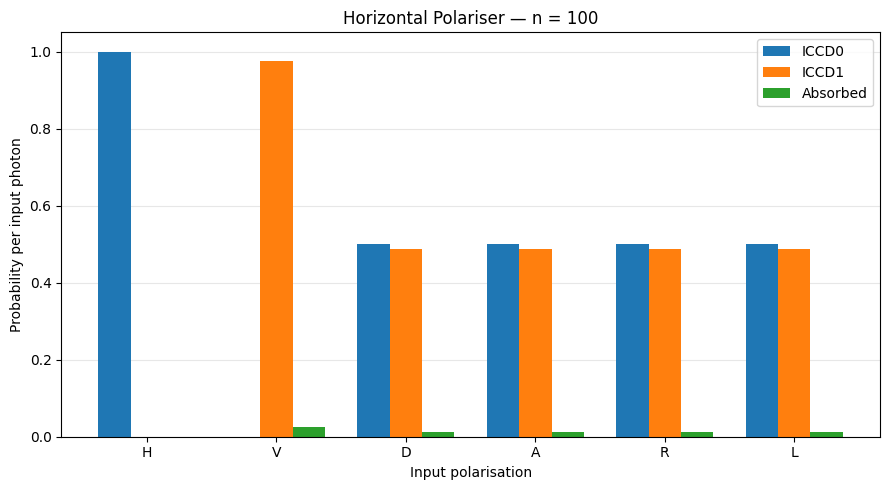


Fitting: Vertical Polariser
Fit converged: True
Recovered Tf: 1.1843232299229527e-09
Recovered Ts: 0.9999999999717624
Recovered theta (degrees): -1.2376198087936424e-12
Measurement residual norm: 5.921232455773159e-09
Recovered SAMPLE Mueller matrix:
 [[ 0.500000000578 -0.499999999394  0.              0.            ]
 [-0.499999999394  0.500000000578 -0.              0.            ]
 [ 0.             -0.              0.000034413998  0.            ]
 [ 0.              0.              0.              0.000034413998]]
Reference matrix:
 [[ 0.5 -0.5  0.   0. ]
 [-0.5  0.5  0.   0. ]
 [ 0.   0.   0.   0. ]
 [ 0.   0.   0.   0. ]]
Frobenius error: 4.8668742136842196e-05
Relative Frobenius error: 4.8668742136842196e-05

Input      P(ICCD0)    P(ICCD1)    P(absorbed)

Physicality check: Recovered sample
Choi eigenvalues: [-0.              0.              0.              1.000000001156]
Completely positive: True
Tr_output(J):
 [[0.000000001184+0.j 0.            +0.j]
 [0.            +0.j 0.999

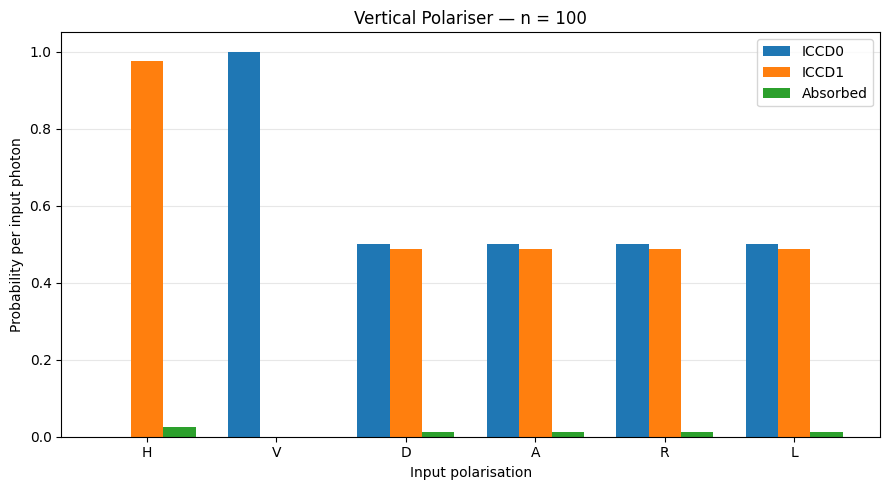


Fitting: +45$^{\circ}$ Polariser
Fit converged: True
Recovered Tf: 0.9999999999956655
Recovered Ts: 2.6445468213312206e-10
Recovered theta (degrees): 45.00000000000066
Measurement residual norm: 9.090224319403551e-10
Recovered SAMPLE Mueller matrix:
 [[ 0.50000000013  -0.              0.499999999866  0.            ]
 [-0.              0.000016262063 -0.              0.            ]
 [ 0.499999999866 -0.              0.50000000013   0.            ]
 [ 0.              0.              0.              0.000016262063]]
Reference matrix:
 [[0.5 0.  0.5 0. ]
 [0.  0.  0.  0. ]
 [0.5 0.  0.5 0. ]
 [0.  0.  0.  0. ]]
Frobenius error: 2.2998029574997757e-05
Relative Frobenius error: 2.2998029574997757e-05

Input      P(ICCD0)    P(ICCD1)    P(absorbed)

Physicality check: Recovered sample
Choi eigenvalues: [-0.             0.             0.             1.00000000026]
Completely positive: True
Tr_output(J):
 [[0.50000000013 +0.j 0.499999999866+0.j]
 [0.499999999866+0.j 0.50000000013 +0.j]]
Eigen

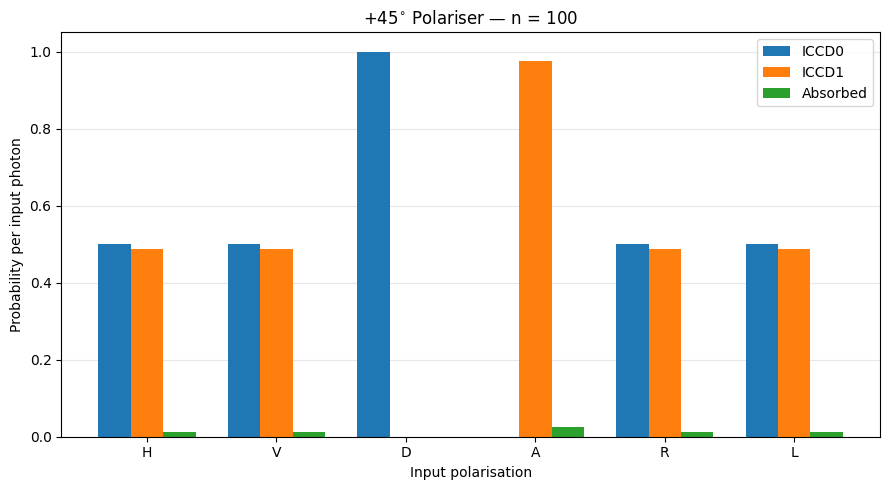


Fitting: -45$^{\circ}$ Polariser
Fit converged: True
Recovered Tf: 0.9999999999618565
Recovered Ts: 3.8703019411023395e-09
Recovered theta (degrees): -45.00000000000094
Measurement residual norm: 8.006042150200299e-09
Recovered SAMPLE Mueller matrix:
 [[ 0.500000001916 -0.             -0.499999998046  0.            ]
 [-0.              0.000062211751  0.              0.            ]
 [-0.499999998046  0.              0.500000001916  0.            ]
 [ 0.              0.              0.              0.000062211751]]
Reference matrix:
 [[ 0.5  0.  -0.5  0. ]
 [ 0.   0.   0.   0. ]
 [-0.5  0.   0.5  0. ]
 [ 0.   0.   0.   0. ]]
Frobenius error: 8.798070184356313e-05
Relative Frobenius error: 8.798070184356313e-05

Input      P(ICCD0)    P(ICCD1)    P(absorbed)

Physicality check: Recovered sample
Choi eigenvalues: [-0.             -0.             -0.              1.000000003832]
Completely positive: True
Tr_output(J):
 [[ 0.500000001916+0.j -0.499999998046+0.j]
 [-0.499999998046+0.j  0.5

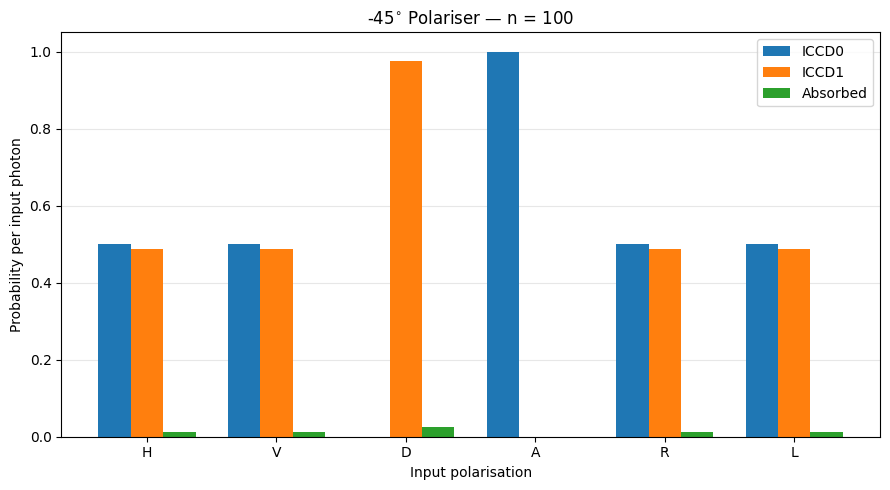


Fitting: 0% Transmission
Fit converged: True
Recovered Tf: 4.736405975368889e-06
Recovered Ts: 5.633557250454223e-07
Recovered theta (degrees): -0.12872680437359704
Measurement residual norm: 5.203079853485877e-07
Recovered SAMPLE Mueller matrix:
 [[ 0.000002649881  0.000002086504 -0.000000009376  0.            ]
 [ 0.000002086504  0.00000264986  -0.000000004567  0.            ]
 [-0.000000009376 -0.000000004567  0.000001633508  0.            ]
 [ 0.              0.              0.              0.000001633488]]
Reference matrix:
 [[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
Frobenius error: 5.299761700414311e-06
Relative Frobenius error: nan

Input      P(ICCD0)    P(ICCD1)    P(absorbed)

Physicality check: Recovered sample
Choi eigenvalues: [-0.             -0.              0.              0.000005299762]
Completely positive: True
Tr_output(J):
 [[ 0.000004736385+0.j -0.000000009376+0.j]
 [-0.000000009376+0.j  0.000000563377+0.j]]
Eigenvalues of I - Tr_output(J): [0.

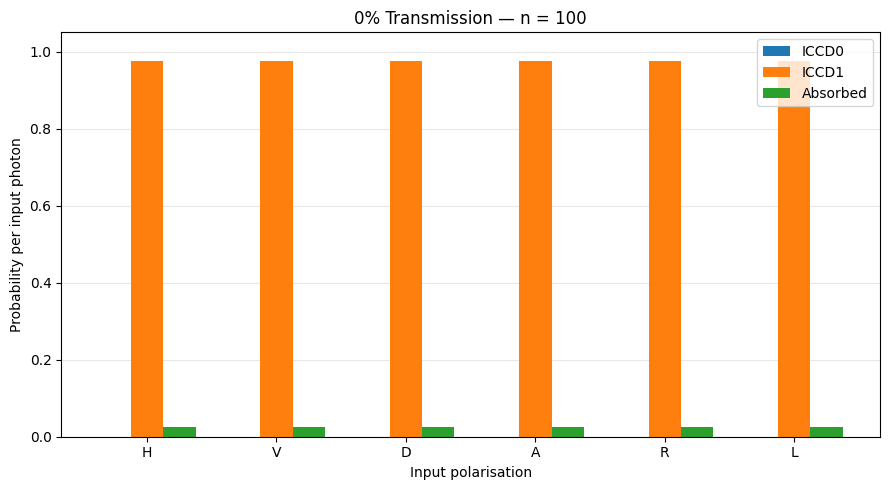


Fitting: 50% Transmission
Fit converged: True
Recovered Tf: 0.4999999999999977
Recovered Ts: 0.4999999999999996
Recovered theta (degrees): 30.000156424145736
Measurement residual norm: 4.1158073681978037e-16
Recovered SAMPLE Mueller matrix:
 [[ 0.5 -0.  -0.   0. ]
 [-0.   0.5 -0.   0. ]
 [-0.   0.   0.5  0. ]
 [ 0.   0.   0.   0.5]]
Reference matrix:
 [[0.5 0.  0.  0. ]
 [0.  0.5 0.  0. ]
 [0.  0.  0.5 0. ]
 [0.  0.  0.  0.5]]
Frobenius error: 3.1616999831336786e-15
Relative Frobenius error: 3.1616999831336786e-15

Input      P(ICCD0)    P(ICCD1)    P(absorbed)

Physicality check: Recovered sample
Choi eigenvalues: [-0. -0.  0.  1.]
Completely positive: True
Tr_output(J):
 [[ 0.5+0.j -0. +0.j]
 [-0. +0.j  0.5+0.j]]
Eigenvalues of I - Tr_output(J): [0.5 0.5]
Trace non-increasing: True
Trace preserving: False
Physical lossy map: True

Physicality check: ICCD0 effective map
Choi eigenvalues: [0.            0.            0.            0.00103327851]
Completely positive: True
Tr_output(J):

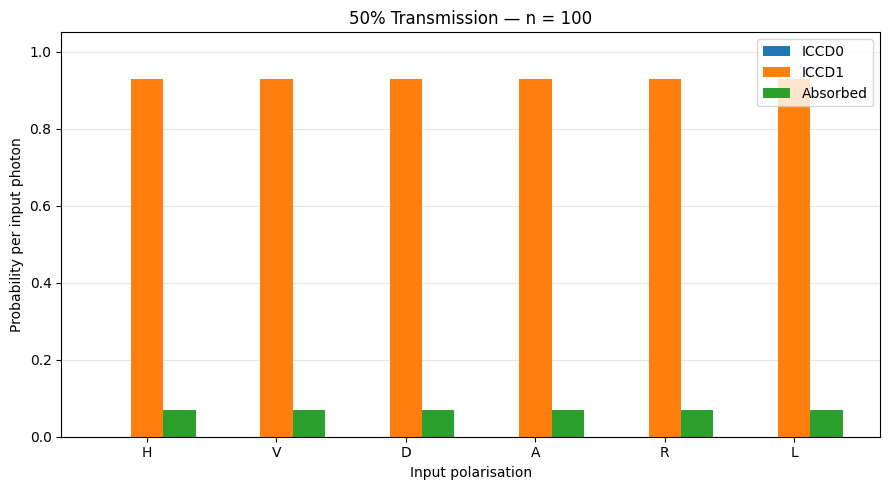


Fitting: 100% Transmission
Fit converged: True
Recovered Tf: 0.9999999996007196
Recovered Ts: 0.9999999994662534
Recovered theta (degrees): 28.496255008534494
Measurement residual norm: 1.6272001561273304e-07
Recovered SAMPLE Mueller matrix:
 [[0.999999999533 0.000000000037 0.000000000056 0.            ]
 [0.000000000037 0.999999999533 0.             0.            ]
 [0.000000000056 0.             0.999999999533 0.            ]
 [0.             0.             0.             0.999999999533]]
Reference matrix:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Frobenius error: 9.378592562848057e-10
Relative Frobenius error: 4.689296281424028e-10

Input      P(ICCD0)    P(ICCD1)    P(absorbed)

Physicality check: Recovered sample
Choi eigenvalues: [-0.             -0.              0.              1.999999999067]
Completely positive: True
Tr_output(J):
 [[0.99999999957 +0.j 0.000000000056+0.j]
 [0.000000000056+0.j 0.999999999497+0.j]]
Eigenvalues of I - Tr_output(J): [0.0000000

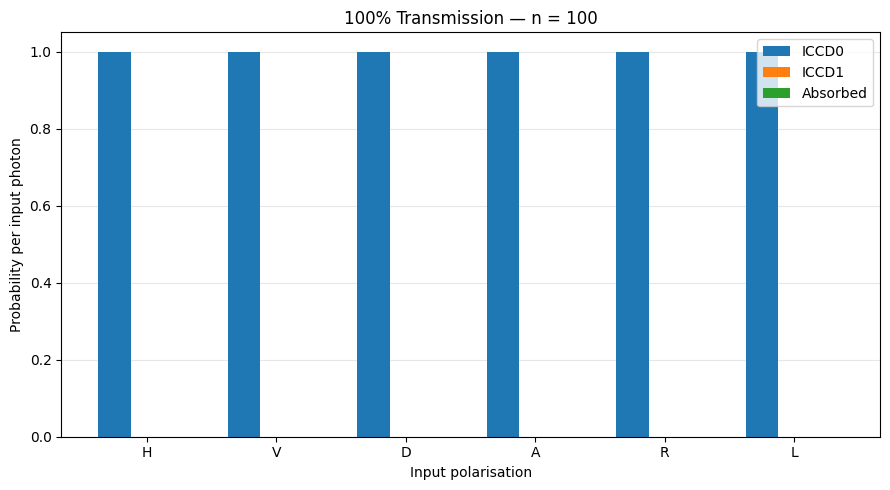

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

# Same ordering as rho_tot_in_list
labels = list(conditional_input_stokes.keys())
X = np.column_stack(
    list(conditional_input_stokes.values())
)
n_test = 100


def mueller_from_jones(J):
    paulis = [I_pol, sigma_z, sigma_x, sigma_y]

    return np.array([
        [
            0.5 * np.trace(
                sigma_mu @ J @ sigma_nu @ dagger(J)
            ).real
            for sigma_nu in paulis
        ]
        for sigma_mu in paulis
    ])


# Fit amplitude transmissions Af and As instead of intensity transmissions.


# CHANGED:
# Fit amplitude transmissions Af, As instead of intensity
# transmissions Tf, Ts.
def residual(parameters, Y0_data, Y1_data, n_steps):

    Af_trial, As_trial, theta_trial = parameters

    # Convert amplitude transmission -> intensity transmission
    Tf_trial = Af_trial**2
    Ts_trial = As_trial**2

    M0_trial, M1_trial, _ = get_mueller(
        n_steps=n_steps,
        theta_axis=theta_trial,
        Tf=Tf_trial,
        Ts=Ts_trial,
        delta=0.0,
        which=1,
    )

    return np.concatenate([
        (M0_trial @ X - Y0_data).ravel(),
        (M1_trial @ X - Y1_data).ravel(),
    ])


cases = [
    {
        "name": "Horizontal Polariser",
        "Tf": 1.0,
        "Ts": 0.0,
        "theta": 0.0,
        "reference": 0.5 * np.array([
            [1, 1, 0, 0],
            [1, 1, 0, 0],
            [0, 0, 0, 0],
            [0, 0, 0, 0],
        ]),
    },

    {
        "name": "Vertical Polariser",
        "Tf": 1.0,
        "Ts": 0.0,
        "theta": np.pi / 2,
        "reference": 0.5 * np.array([
            [ 1, -1, 0, 0],
            [-1,  1, 0, 0],
            [ 0,  0, 0, 0],
            [ 0,  0, 0, 0],
        ]),
    },

    {
        "name": "+45$^{\\circ}$ Polariser",
        "Tf": 1.0,
        "Ts": 0.0,
        "theta": np.pi / 4,
        "reference": 0.5 * np.array([
            [1, 0, 1, 0],
            [0, 0, 0, 0],
            [1, 0, 1, 0],
            [0, 0, 0, 0],
        ]),
    },

    {
        "name": "-45$^{\\circ}$ Polariser",
        "Tf": 1.0,
        "Ts": 0.0,
        "theta": -np.pi / 4,
        "reference": 0.5 * np.array([
            [ 1, 0, -1, 0],
            [ 0, 0,  0, 0],
            [-1, 0,  1, 0],
            [ 0, 0,  0, 0],
        ]),
    },
    {
        "name": "0% Transmission",
        "Tf": 0.0,
        "Ts": 0.0,
        "theta": 0.0,
        "reference": np.zeros((4, 4)),
    },

    {
        "name": "50% Transmission",
        "Tf": 0.50,
        "Ts": 0.50,
        "theta": 0.0,
        "reference": 0.50 * np.eye(4),
    },

    {
        "name": "100% Transmission",
        "Tf": 1.0,
        "Ts": 1.0,
        "theta": 0.0,
        "reference": np.eye(4),
    }
]

results = {}
np.set_printoptions(precision=12, suppress=True)

for case in cases:
    print(f"\nFitting: {case['name']}", flush=True)

    # 1. Generate synthetic camera measurements
    M0_measured, M1_measured, _ = get_mueller(
        n_steps=n_test,
        theta_axis=case["theta"],
        Tf=case["Tf"],
        Ts=case["Ts"],
        delta=0.0,
        which=1,
    )

    Y0_measured = M0_measured @ X
    Y1_measured = M1_measured @ X

    # 2. Calculate probabilities for each input
    # S0 is the first row of each output Stokes matrix.
    P_iccd0 = Y0_measured[0, :].copy()
    P_iccd1 = Y1_measured[0, :].copy()
    P_absorbed = 1.0 - P_iccd0 - P_iccd1

    probabilities = np.array([
        P_iccd0, P_iccd1, P_absorbed
    ])

    if not np.all(np.isfinite(probabilities)):
        raise ValueError("Non-finite probabilities.")

    if (
        np.any(probabilities < -1e-9)
        or np.any(probabilities > 1 + 1e-9)
    ):
        raise ValueError("Probabilities outside [0, 1].")

    # Remove only tiny numerical excursions for display
    plot_probabilities = np.clip(probabilities, 0.0, 1.0)

    # 3. Fit the three unknown sample parameters
    fits = []

    for theta_start in np.deg2rad([0, 30, 60, 90]):

        fit = least_squares(
            residual,

            # CHANGED:
            # Starting values are now amplitudes, not intensities.
            x0=[
                np.sqrt(0.8),
                np.sqrt(0.2),
                theta_start
            ],

            bounds=(
                [0.0, 0.0, -np.pi/2],
                [1.0, 1.0,  np.pi/2],
            ),

            args=(Y0_measured, Y1_measured, n_test),

            xtol=1e-12,
            ftol=1e-12,
            gtol=1e-12,
            max_nfev=10000000000,
        )

        fits.append(fit)

    converged = [fit for fit in fits if fit.success]
    candidates = converged if converged else fits

    best = min(
        candidates,
        key=lambda fit: np.linalg.norm(fit.fun),
    )

    # CHANGED:
    # Optimiser gives amplitude transmissions.
    Af_fit, As_fit, theta_fit = best.x

    # Convert back to intensity transmissions.
    Tf_fit = Af_fit**2
    Ts_fit = As_fit**2

    # 4. Construct the recovered SAMPLE Mueller matrix
    J_recovered = J_present(
        theta_axis=theta_fit,
        Tf=Tf_fit,
        Ts=Ts_fit,
        delta=0.0,
    )

    M_recovered = mueller_from_jones(J_recovered)
    M_reference = case["reference"]
    
    # 5. Check the recovered sample and effective detector maps.
    sample_check = check_mueller_physicality(M_recovered)
    iccd0_check = check_mueller_physicality(M0_measured)
    iccd1_check = check_mueller_physicality(M1_measured)

    # Sum of the two detector maps: all surviving photons.
    M_surviving = M0_measured + M1_measured
    surviving_check = check_mueller_physicality(M_surviving)

    # 5. Compare with the reference
    error_F = np.linalg.norm(
        M_recovered - M_reference, ord="fro"
    )

    reference_norm = np.linalg.norm(M_reference, ord="fro")
    relative_error_F = (
        error_F / reference_norm
        if reference_norm > 0
        else np.nan
    )

    results[case["name"]] = {
        "fit": best,
        "M_recovered": M_recovered,
        "M_reference": M_reference,
        "error_F": error_F,
        "relative_error_F": relative_error_F,
        "P_iccd0": P_iccd0,
        "P_iccd1": P_iccd1,
        "P_absorbed": P_absorbed,
        "sample_physicality": sample_check,
        "iccd0_physicality": iccd0_check,
        "iccd1_physicality": iccd1_check,
        "surviving_physicality": surviving_check,
    }
    print("Fit converged:", best.success)
    print("Recovered Tf:", Tf_fit)
    print("Recovered Ts:", Ts_fit)
    print("Recovered theta (degrees):", np.rad2deg(theta_fit))
    print("Measurement residual norm:", np.linalg.norm(best.fun))
    print("Recovered SAMPLE Mueller matrix:\n", M_recovered)
    print("Reference matrix:\n", M_reference)
    print("Frobenius error:", error_F)
    print("Relative Frobenius error:", relative_error_F)

    print("\nInput      P(ICCD0)    P(ICCD1)    P(absorbed)")

    
    print_physicality("Recovered sample", sample_check)
    print_physicality("ICCD0 effective map", iccd0_check)
    print_physicality("ICCD1 effective map", iccd1_check)
    print_physicality("Combined surviving map", surviving_check)
    

    for i, label in enumerate(labels):
        print(
            f"{label:<10} "
            f"{P_iccd0[i]:.6f}    "
            f"{P_iccd1[i]:.6f}    "
            f"{P_absorbed[i]:.6f}"
        )

    # 6. One probability plot for this sample
    positions = np.arange(len(labels))
    width = 0.25

    fig, ax = plt.subplots(figsize=(9, 5))

    for offset, values, legend_label in zip(
        [-width, 0, width],
        plot_probabilities,
        ["ICCD0", "ICCD1", "Absorbed"],
    ):
        ax.bar(
            positions + offset,
            values,
            width,
            label=legend_label,
        )

    ax.set_xticks(positions)
    ax.set_xticklabels(labels)
    ax.set_xlabel("Input polarisation")
    ax.set_ylabel("Probability per input photon")
    ax.set_ylim(0, 1.05)
    ax.set_title(f"{case['name']} — n = {n_test}")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.legend()

    fig.tight_layout()
    plt.show()

## Comparing all samples at 100 cycles

This cell plots the probabilities stored in `results`, without repeating the simulation or fitting. Each row shows one reference sample. For each input polarisation, the three bars give the probabilities of reaching ICCD0, reaching ICCD1 and being absorbed. Together, they should add up to 1. The commented-out check adds only the two detector probabilities, which gives the survival probability.

For a horizontal polariser, H input reaches ICCD0 without absorption. V input is aligned with the absorbing axis, so at 100 cycles most surviving photons reach ICCD1. D, A, R and L contain equal amounts of H and V and therefore give the same detector and absorption probabilities. Rotating the polariser changes which inputs align with its transmitting and absorbing axes. The 0% transmission sample blocks both polarisations, while the 100% transmission sample behaves as if no sample were present.

The plotted probabilities come from simulations using the **reference sample parameters**, not the fitted parameters. Small numerical deviations outside [0,1] are clipped for display. The boxes show each sample’s single-pass intensity transmissions and orientation, while the horizontal axis lists the six input polarisations.


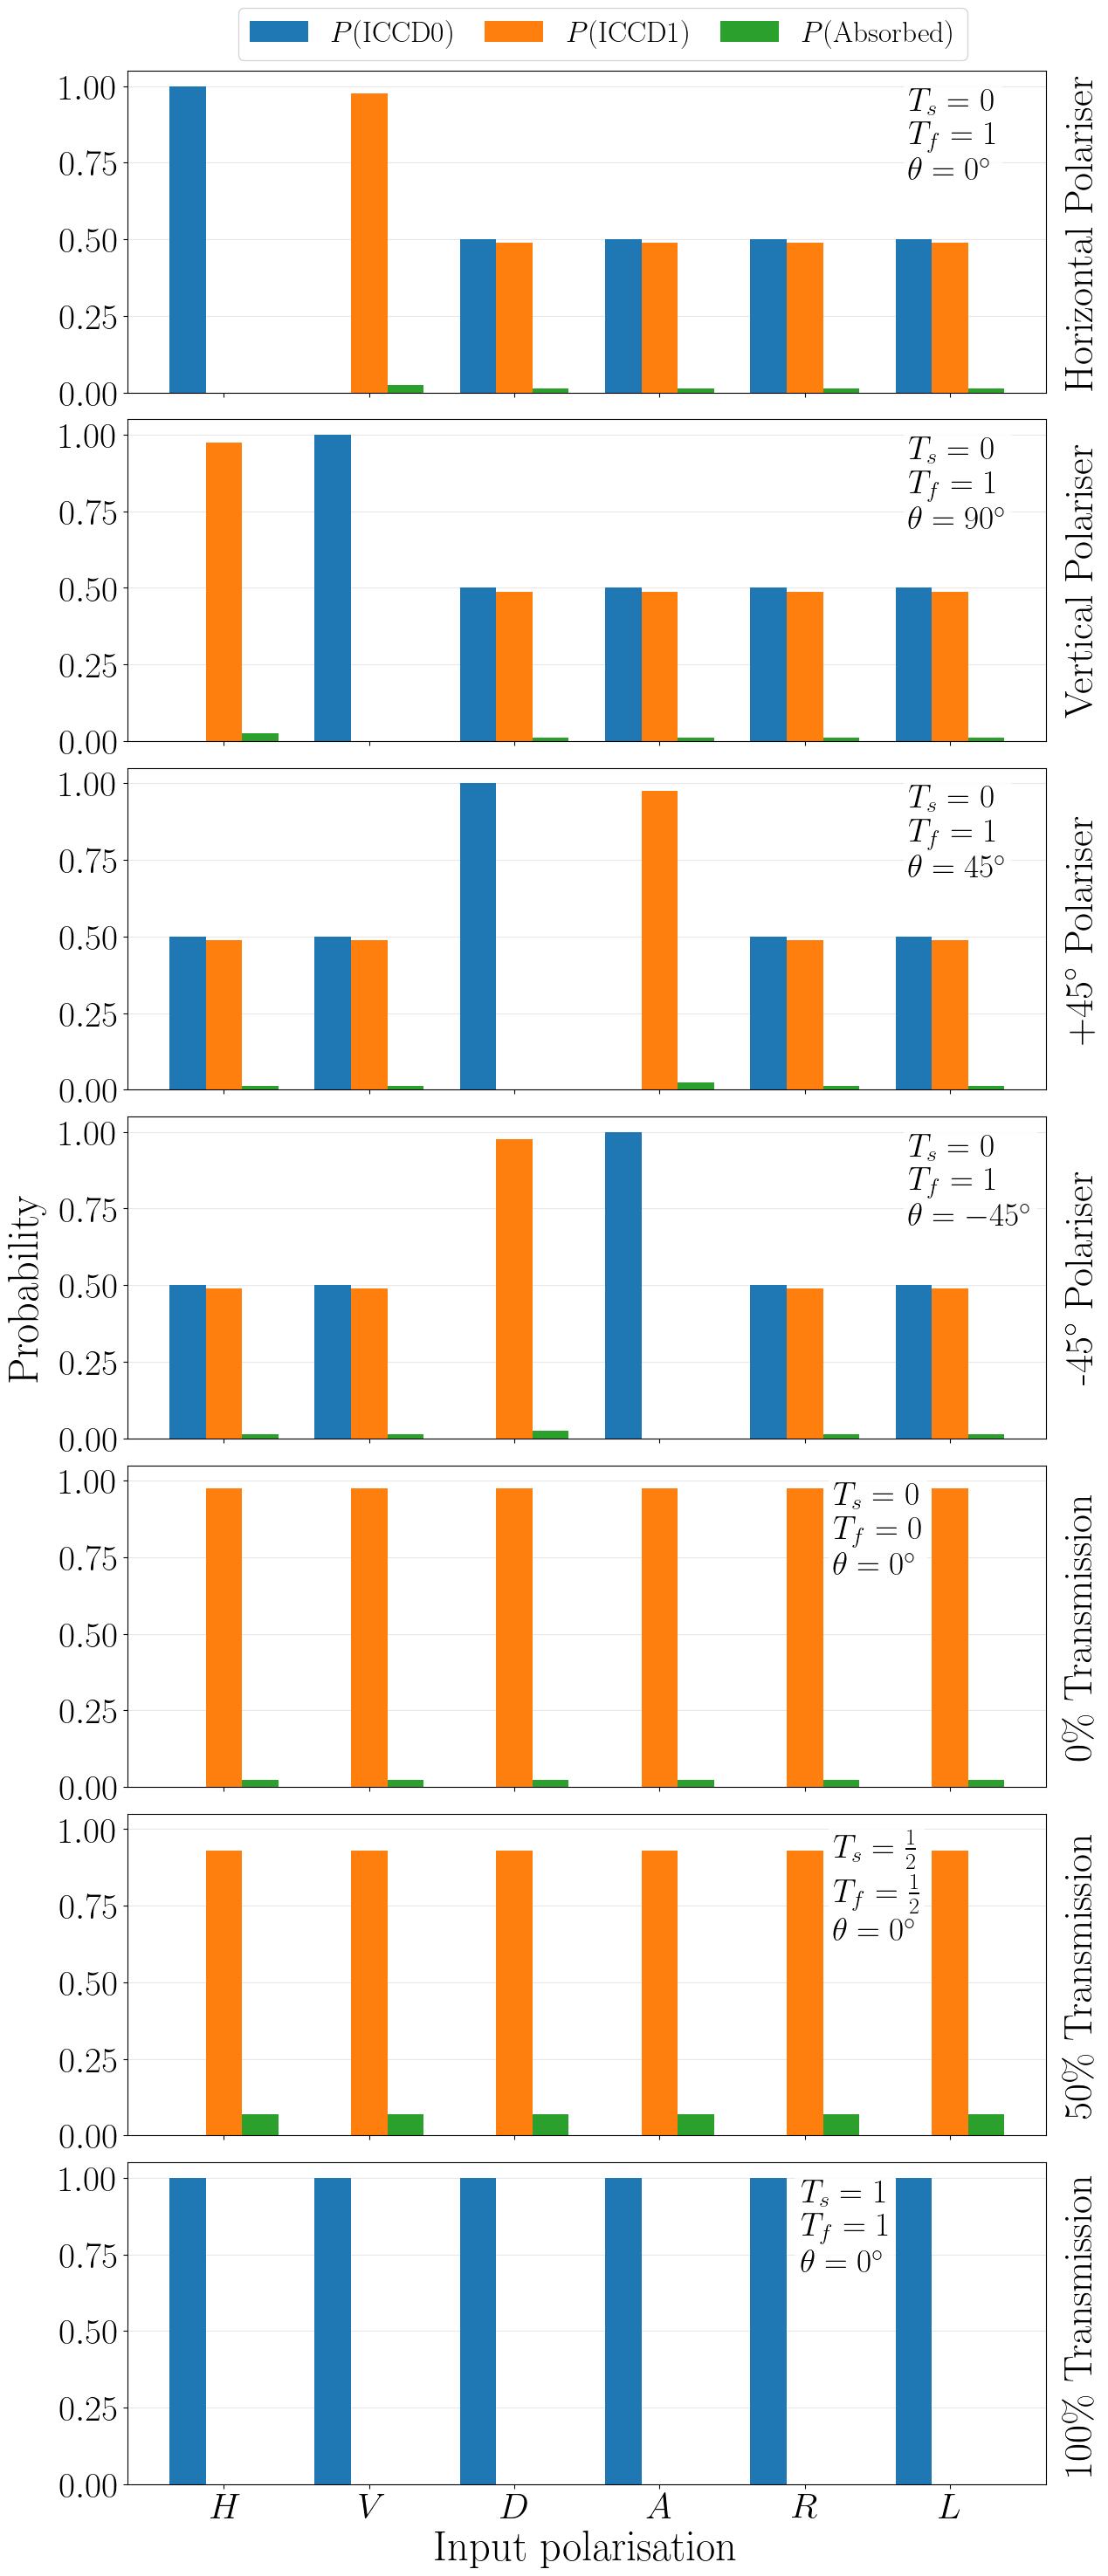

In [20]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MaxNLocator


plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 9,
})


def latex_escape(text):
    """Escape special LaTeX characters in normal text."""
    replacements = {
        "\\": r"\textbackslash{}",
        "&": r"\&",
        "%": r"\%",
        "$": r"\$",
        "#": r"\#",
        "_": r"\_",
        "{": r"\{",
        "}": r"\}",
        "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}",
    }

    return "".join(replacements.get(char, char) for char in str(text))



fig, axes = plt.subplots(
    nrows=len(cases),
    ncols=1,
    figsize=(12, 4.2 * len(cases)),
    sharex=True,
    sharey=True,
    squeeze=False,
    constrained_layout=True,
)

positions = np.arange(len(labels))
width = 0.25



for ax, case in zip(axes[:, 0], cases):
    result = results[case["name"]]
    '''total_probability = (
        np.asarray(result["P_iccd0"])
        + np.asarray(result["P_iccd1"])
    )

    print(f"\n{case['name']}")
    for input_label, total in zip(labels, total_probability):
        print(f"  {input_label}: {total:.12f}")

    print(
        "All sum to 1:",
        np.allclose(total_probability, 1.0, atol=1e-10, rtol=0),
    )'''

    if np.isclose(case["Ts"], 0.5) and np.isclose(case["Tf"], 0.5):
        label = (
            r"$T_s=\frac{1}{2}$" "\n"
            r"$T_f=\frac{1}{2}$" "\n"
            rf"$\theta={np.rad2deg(case['theta']):.0f}^\circ$"
        )
    else:
        label = (
            rf"$T_s={case['Ts']:.2g}$" "\n"
            rf"$T_f={case['Tf']:.2g}$" "\n"
            rf"$\theta={np.rad2deg(case['theta']):.0f}^\circ$"
        )


    if ax is axes[-1, 0]:
        x, y = 0.7325, 0.95 
    elif any(ax is last_ax for last_ax in axes[-3:-1, 0]):
        x, y = 0.768, 0.95  
    else:
        x, y = 0.85, 0.95 
        

    ax.text(
        x, y,
        label,
        transform=ax.transAxes,
        fontsize=27,
        ha="left",
        va="top",
        bbox=dict(
            facecolor="white",
            alpha=0.85,
            edgecolor="none",
        ),
    )
    # Bars
    for offset, key, legend_label in zip(
        [-width, 0, width],
        ["P_iccd0", "P_iccd1", "P_absorbed"],
        [
            r"$P(\mathrm{ICCD0})$",
            r"$P(\mathrm{ICCD1})$",
            r"$P(\mathrm{Absorbed})$",
        ],
    ):
        ax.bar(
            positions + offset,
            np.clip(result[key], 0, 1),
            width,
            label=legend_label,
        )



    case_name = case["name"].strip()
    case_name = case_name.replace(" degree", r"$^{\circ}$")
    case_name = case_name.replace(r"\%", "%").replace("%", r"\%")

    ax.text(
        1.02, 0.5,
        case_name,
        transform=ax.transAxes,
        rotation=90,
        va="center",
        ha="left",
        fontsize=33,
        clip_on=False,
    )

    ax.set_ylim(0, 1.05)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

    ax.set_xticks(positions)


    ax.set_xticklabels(
        [rf"${label}$" for label in labels],
        fontsize=30,
    )

    ax.tick_params(
        axis="y",
        which="major",
        labelsize=30,
    )

    ax.tick_params(
        axis="x",
        bottom=True,
        labelbottom=(ax is axes[-1, 0]),
        labelsize=30,
    )




    # Grid
    ax.grid(
        axis="y",
        alpha=0.3,
    )

    ax.set_axisbelow(True)

fig.supylabel(
    "Probability",
    fontsize=35,
    x=-0.045,
    y=0.5,
)
axes[0, 0].legend(
    ncol=3,
    loc="upper right",
    bbox_to_anchor=(0.93, 1.24),
    fontsize=24,
    columnspacing=1,
)


axes[-1, 0].set_xlabel(
    "Input polarisation",
    fontsize=35,
)

plt.savefig('main_result_grid.pdf', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

## Calculating absorption and port asymmetry for cycles 1–100

This cell calculates the absorption and detector probabilities for all seven samples and six input polarisations, using cycle counts from 1 to 100. For each cycle count $n$, the beam-splitter angle is set to $\pi/(4n)$.

The absorption probability is calculated from the probability missing from the final state:

$$
P_{\mathrm{abs}}(n)=1-\operatorname{Tr}(\rho_{\mathrm{out}}(n)).
$$

The difference between the two detector probabilities is normalised by their sum:

$$
D(n)=\frac{P_{\mathrm{ICCD0}}-P_{\mathrm{ICCD1}}}
{P_{\mathrm{ICCD0}}+P_{\mathrm{ICCD1}}}.
$$

This tells us how the surviving photons are distributed between the detectors. Positive $D$ means more photons reach ICCD0, negative $D$ means more reach ICCD1, and $D=0$ means equal probabilities. It is a detector imbalance, not a probability of correctly identifying the sample. If the survival probability is too small to calculate the ratio reliably, `D` is stored as `NaN`.

The results are saved in `absorption_results` for each sample. The arrays `P_absorbed` and `D` each have six rows, one for each input polarisation, and 100 columns, one for each cycle count. Each input is kept separately; no averaging is performed. The code checks that absorption lies within [0,1], allowing for rounding errors, and that the detector probabilities add up to the survival probability.

In [21]:
import numpy as np

n_values = np.arange(1, 101)
labels = list(conditional_input_stokes.keys())

rho_inputs = [
    np.kron(
        P2,
        density_from_stokes(
            conditional_input_stokes[label],
            enforce_normalised=True,
        ),
    )
    for label in labels
]

absorption_results = {}

for case in cases:
    print(f"Calculating absorption: {case['name']}", flush=True)

    P_absorbed = np.zeros((len(labels), len(n_values)))
    D_values = np.full_like(P_absorbed, np.nan)

    for j, n in enumerate(n_values):
        for i, rho_in in enumerate(rho_inputs):
            stokes0, stokes1, survival, _ = simulate_stokes_out(
                which=1,
                n_steps=int(n),
                theta_axis=case["theta"],
                Tf=case["Tf"],
                Ts=case["Ts"],
                delta=0.0,
                rho_tot_in=rho_in,
            )

            P_absorbed[i, j] = 1.0 - survival

            prob_iccd0 = stokes0[0]
            prob_iccd1 = stokes1[0]
            detected_probability = prob_iccd0 + prob_iccd1

            if not np.isclose(
                detected_probability,
                survival,
                atol=1e-10,
                rtol=0,
            ):
                print(
                    "Mismatch:",
                    "Detector sum =", detected_probability,
                    "Survival =", survival,
                )

            if detected_probability > 1e-12:
                D_values[i, j] = (
                    (prob_iccd0 - prob_iccd1)
                    / detected_probability
                )

    if (
        not np.all(np.isfinite(P_absorbed))
        or np.any(P_absorbed < -1e-9)
        or np.any(P_absorbed > 1 + 1e-9)
    ):
        raise ValueError(
            f"Invalid absorption probabilities for {case['name']}"
        )

    absorption_results[case["name"]] = {
        "n": n_values.copy(),
        "labels": labels.copy(),
        "P_absorbed": P_absorbed.copy(),
        "D": D_values.copy(),
    }

Calculating absorption: Horizontal Polariser
Calculating absorption: Vertical Polariser
Calculating absorption: +45$^{\circ}$ Polariser
Calculating absorption: -45$^{\circ}$ Polariser
Calculating absorption: 0% Transmission
Calculating absorption: 50% Transmission
Calculating absorption: 100% Transmission


## Plotting the absorption curves

Each panel shows the probability of absorption over the whole protocol as the number of cycles increases. The six curves represent H, V, D, A, R and L inputs. The data come from `absorption_results`, so this cell only plots the results without repeating the simulation.

Even a fully opaque sample can give low absorption in the interferometer because most of the photon’s amplitude remains in the empty path. For an input aligned with an ideal polariser’s blocked axis, absorption decreases approximately as $\pi^2/(4n)$ at large $n$.

For a horizontal polariser, H input has zero absorption, while V input gives the blocked-axis absorption. D, A, R and L each have half their population on the blocked axis, so their absorption is half that of V. A polarisation-independent sample gives the same absorption for all six inputs. Some curves therefore overlap.

Small numerical deviations outside [0,1] are clipped for plotting without changing the stored data. 

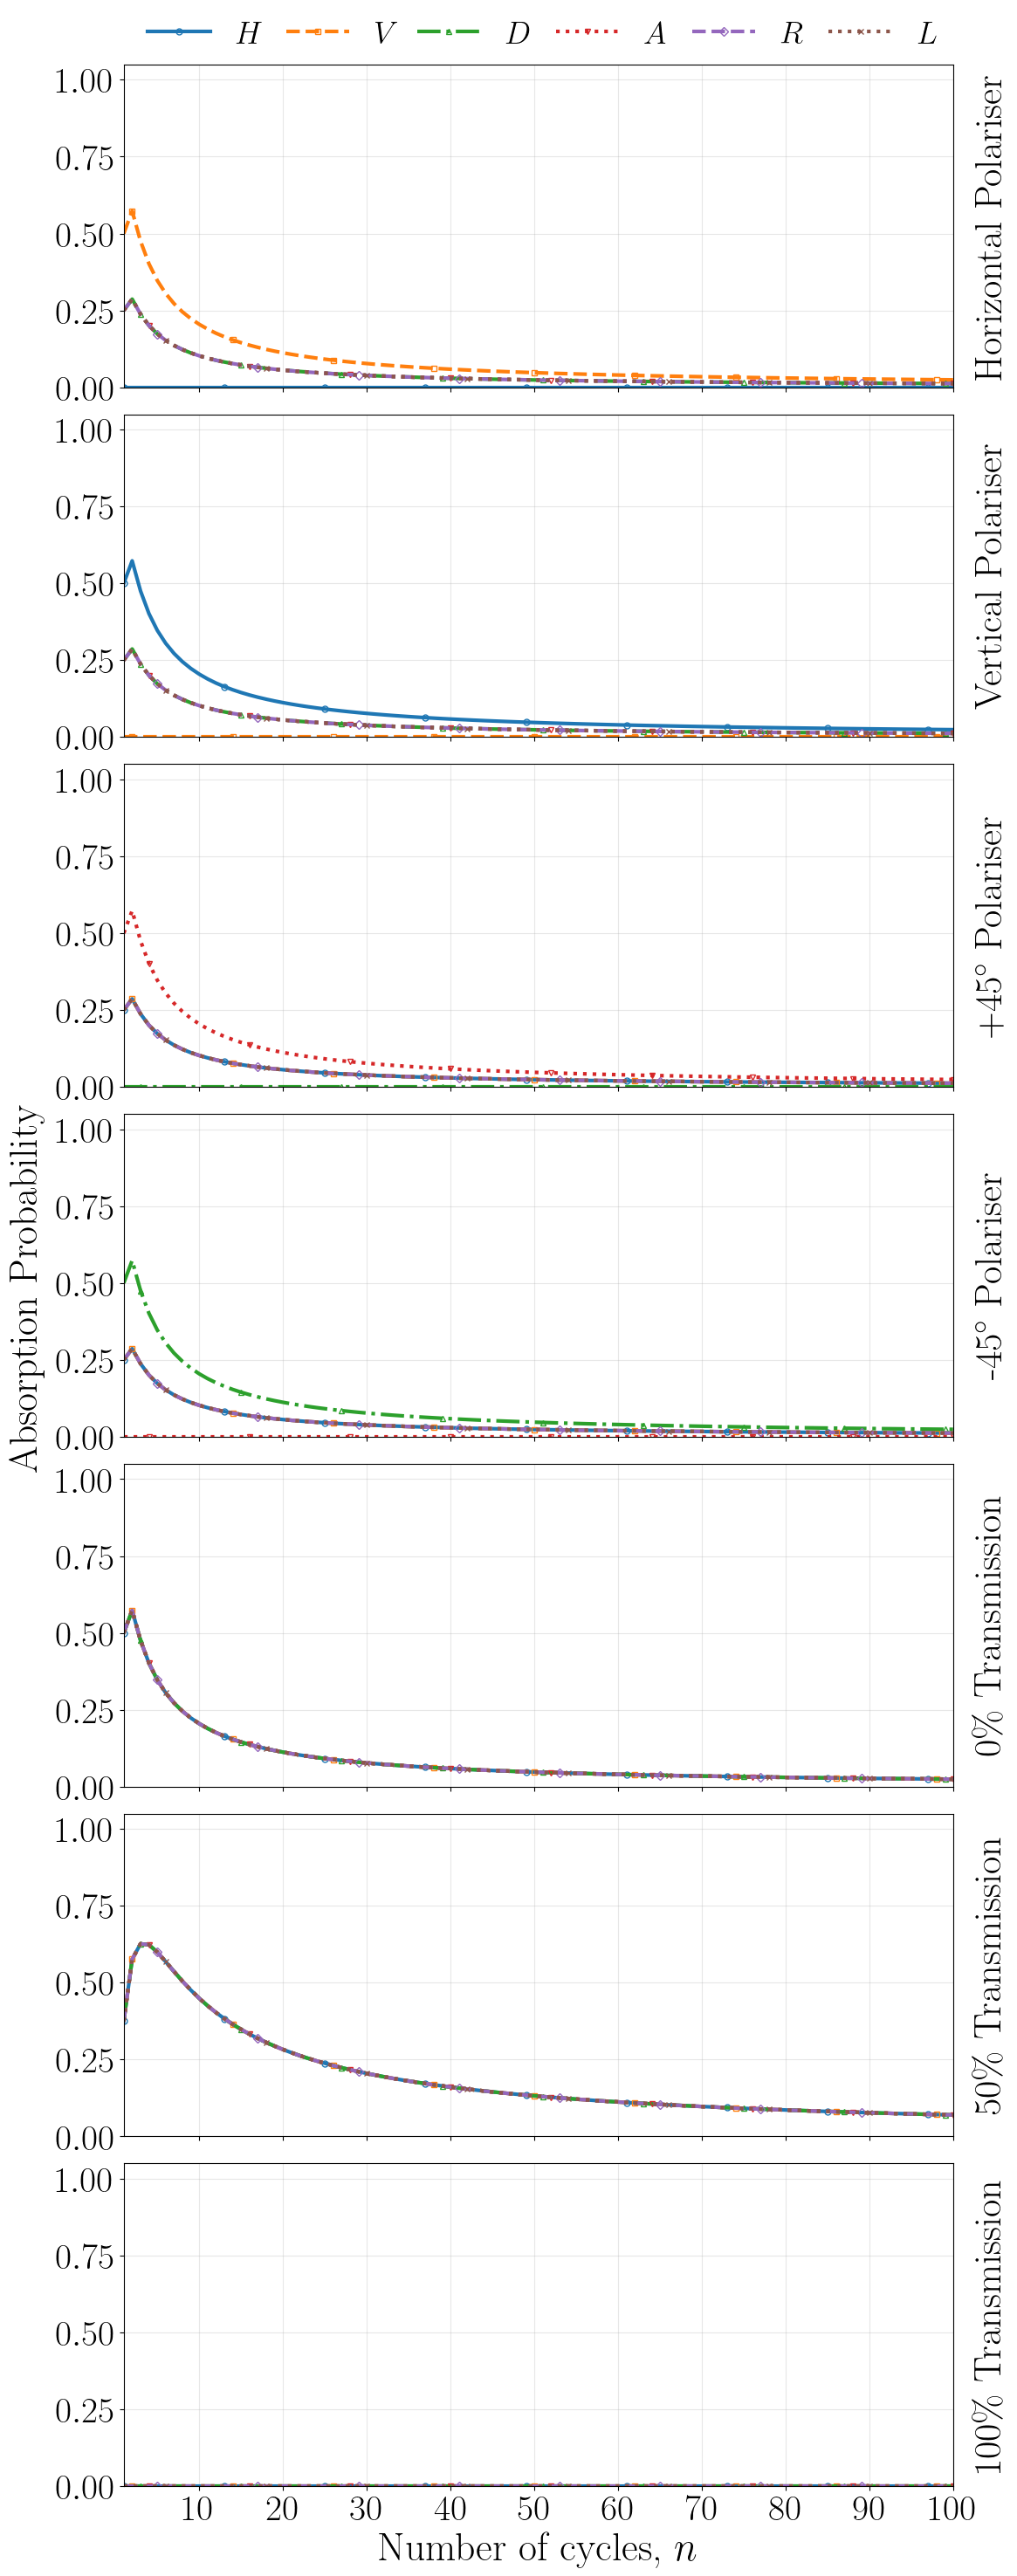

In [22]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 9,
})

fig, axes = plt.subplots(
    nrows=len(cases),
    ncols=1,
    figsize=(11, 4.2 * len(cases)),
    sharex=True,
    sharey=True,
    squeeze=False,
    constrained_layout=True,
)

line_styles = ["-", "--", "-.", ":", "--", ":"]
markers = ["o", "s", "^", "v", "D", "x"]

for row, (ax, case) in enumerate(zip(axes[:, 0], cases)):
    data = absorption_results[case["name"]]

    # Clip tiny floating-point excursions for display only.
    plot_values = np.clip(data["P_absorbed"], 0.0, 1.0)

    for i, label in enumerate(data["labels"]):
        ax.plot(
            data["n"],
            plot_values[i],
            label=rf"${label}$",
            linewidth=3,
            linestyle=line_styles[i % len(line_styles)],
            marker=markers[i % len(markers)],
            markersize=5,
            markerfacecolor="none",
            markevery=(i, 12),
        )

    case_name = case["name"].strip()
    case_name = case_name.replace(" degree", r"$^{\circ}$")
    case_name = case_name.replace(r"\%", "%").replace("%", r"\%")

    ax.text(
        1.025, 0.5,
        case_name,
        transform=ax.transAxes,
        rotation=90,
        va="center",
        ha="left",
        fontsize=32,
        clip_on=False,
    )

    ax.set_ylim(0, 1.05)
    ax.set_xlim(data["n"][0], data["n"][-1])
    ax.tick_params(axis="both", labelsize=30)
    ax.tick_params(
        axis="x",
        labelbottom=(row == len(cases) - 1),
    )
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.xaxis.set_major_locator(MaxNLocator(nbins=10))
    ax.set_axisbelow(True)
    ax.grid(True, axis="both", alpha=0.3)

handles, legend_labels = axes[0, 0].get_legend_handles_labels()

axes[0, 0].legend(
    handles,
    legend_labels,
    ncol=6,
    loc="lower center",
    bbox_to_anchor=(0.505, 0.96),
    fontsize=26,
    columnspacing=0.79,
    frameon=False,
)

fig.supylabel(
    "Absorption Probability",
    fontsize=33,
    x=-0.045,
    y=0.5,
)

axes[-1, 0].set_xlabel(
    r"Number of cycles, $n$",
    fontsize=33,
)

fig.savefig(
    "absoroption.pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.show()

## Plotting the port imbalance

This cell plots the stored values of `D`, which compare the probabilities of reaching the two detectors:

$$
D=\frac{P_{\mathrm{ICCD0}}-P_{\mathrm{ICCD1}}}
{P_{\mathrm{ICCD0}}+P_{\mathrm{ICCD1}}}.
$$

When $D=+1$, all detected photons reach ICCD0. When $D=-1$, they all reach ICCD1. At $D=0$, the two detectors are equally likely. This ratio only describes the photons that survive, so the absorption curves are needed to see how many photons are lost.

For an ideal polariser, an input aligned with the transmitting axis gives $D\simeq+1$. An input aligned with the absorbing axis gives $D=-1$ as the number of cycles increases. A fully transparent sample sends photons to ICCD0, while a fully opaque sample sends most surviving photons to ICCD1 at large cycle counts.


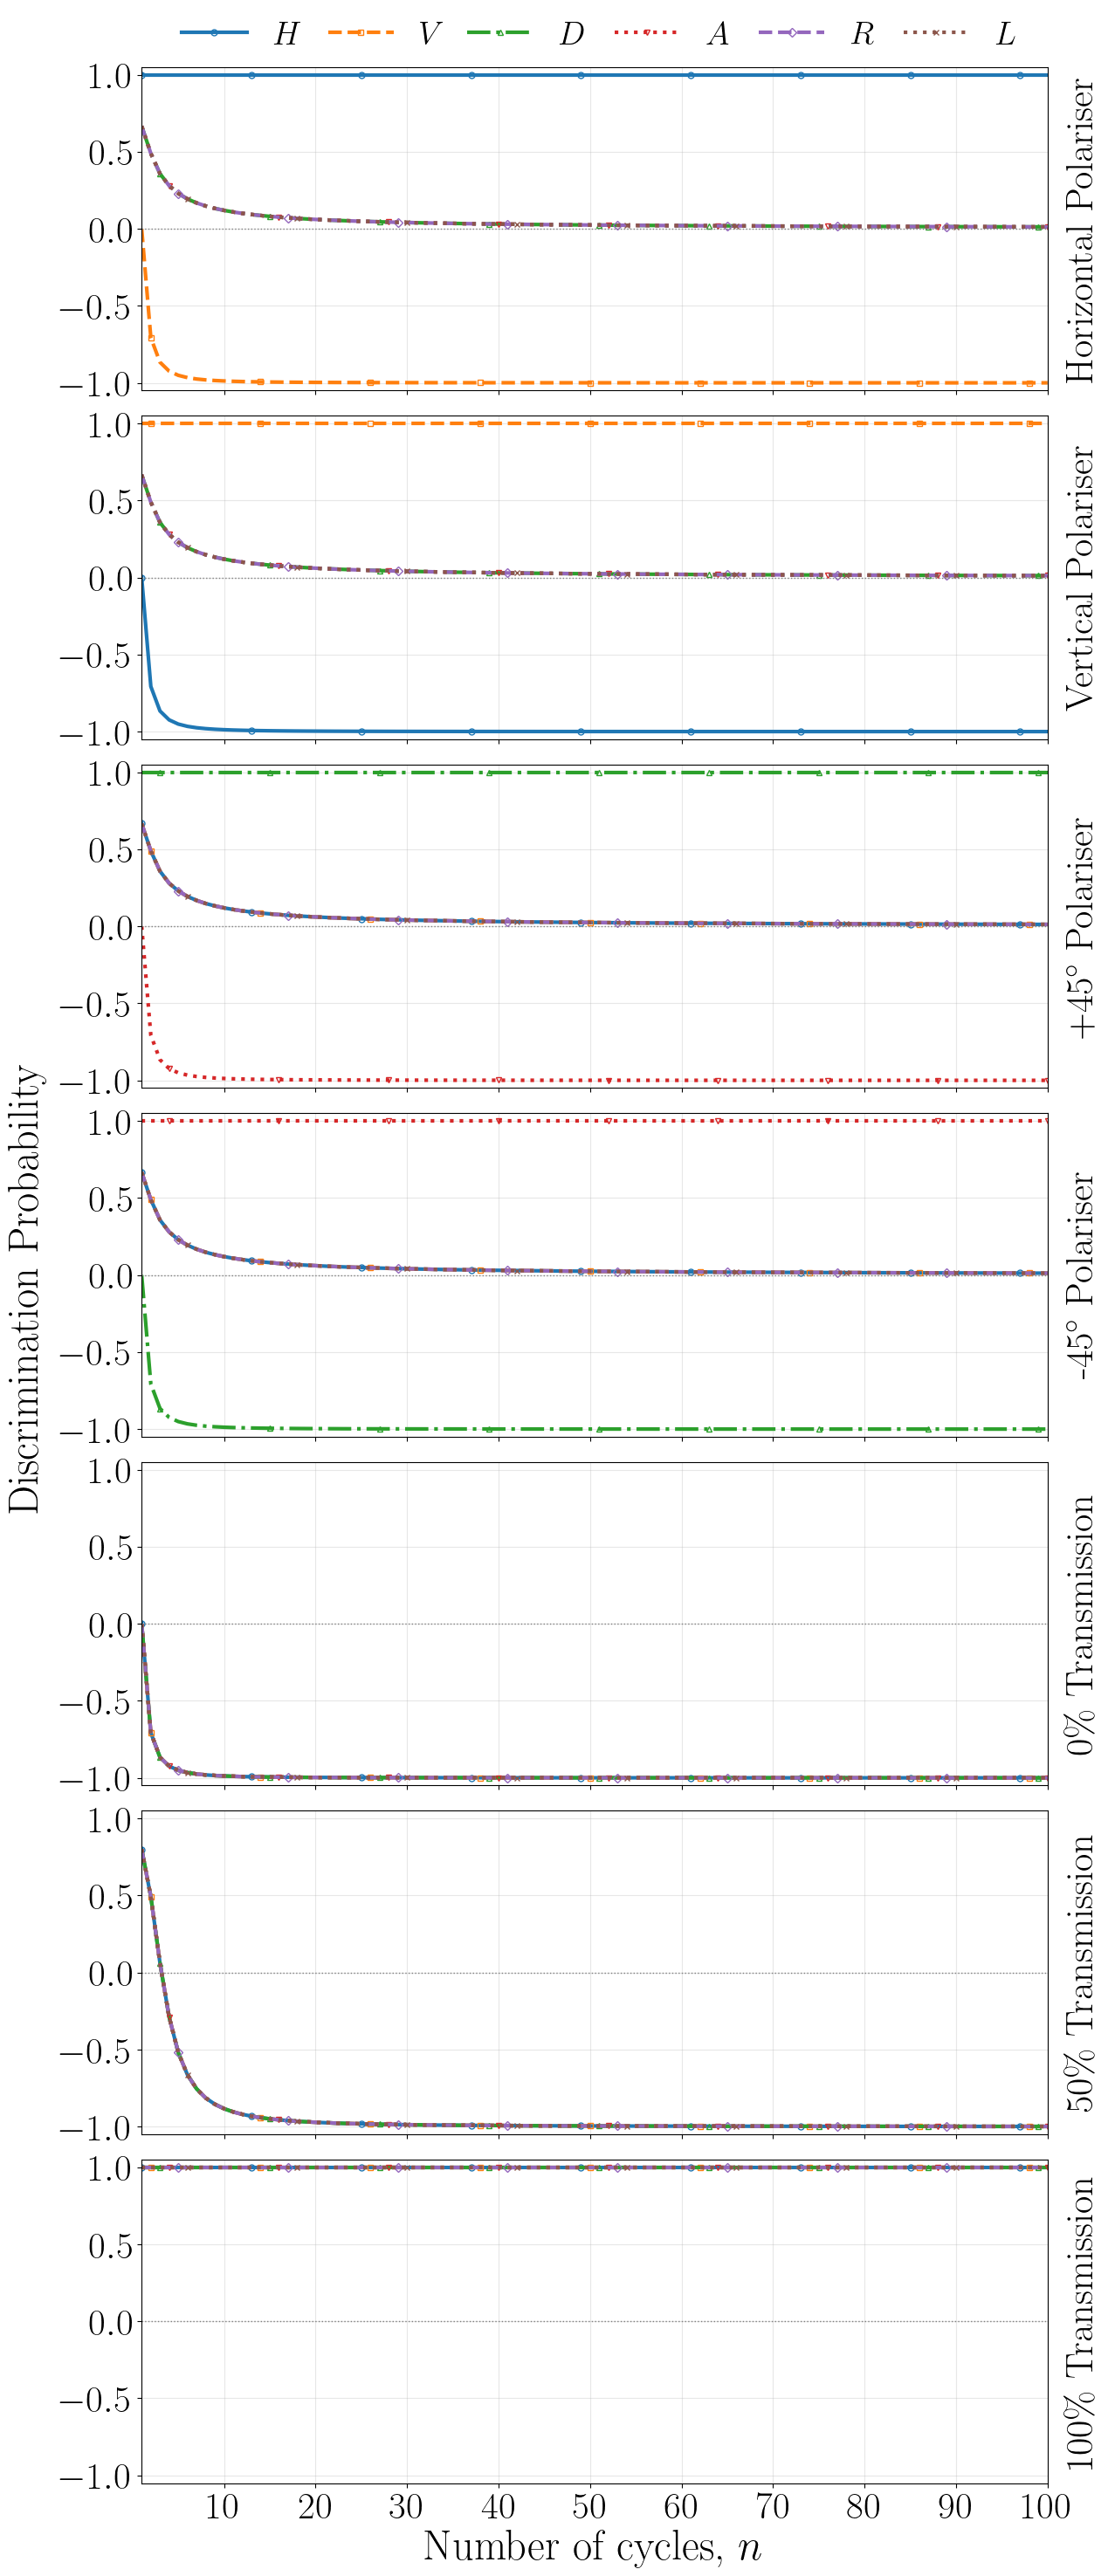

In [23]:
fig_D, axes_D = plt.subplots(
    nrows=len(cases),
    ncols=1,
    figsize=(12, 4.2 * len(cases)),
    sharex=True,
    sharey=True,
    squeeze=False,
    constrained_layout=True,
)

styles_D = ["-", "--", "-.", ":", "--", ":"]
markers_D = ["o", "s", "^", "v", "D", "x"]

for ax_D, case in zip(axes_D[:, 0], cases):
    data = absorption_results[case["name"]]

    for i, input_label in enumerate(data["labels"]):
        ax_D.plot(
            data["n"],
            data["D"][i],
            label=rf"${input_label}$",
            linewidth=3,
            linestyle=styles_D[i % len(styles_D)],
            marker=markers_D[i % len(markers_D)],
            markersize=5,
            markerfacecolor="none",
            markevery=(i, 12),
        )

    case_name = case["name"].strip()
    case_name = case_name.replace(" degree", r"$^{\circ}$")
    case_name = case_name.replace(r"\%", "%").replace("%", r"\%")


    
    ax_D.text(
        1.02, 0.5,
        case_name,
        transform=ax_D.transAxes,
        rotation=90,
        va="center",
        ha="left",
        fontsize=32,
        clip_on=False,
    )

    ax_D.axhline(0, color="grey", linestyle=":", linewidth=1)
    ax_D.set_ylim(-1.05, 1.05)
    ax_D.set_xlim(data["n"][0], data["n"][-1])
    ax_D.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax_D.xaxis.set_major_locator(MaxNLocator(nbins=10))

    
    ax_D.tick_params(
        axis="both",
        labelsize=31
    )
    ax_D.tick_params(
    axis="x",
    labelbottom=(ax_D is axes_D[-1, 0]),
    )
    ax_D.grid(alpha=0.3)
    ax_D.set_axisbelow(True)

axes_D[0, 0].legend(
    handles,
    legend_labels,
    ncol=6,
    loc="lower center",
    bbox_to_anchor=(0.505, 0.96),
    fontsize=27,
    columnspacing=0.88,
    frameon=False,
)

fig_D.supylabel(
    "Discrimination Probability",
    fontsize=35,
    x=-0.045,
    y=0.5,
)

axes_D[-1, 0].set_xlabel(
    r"Number of cycles, $n$",
    fontsize=35,
)

fig_D.savefig(
    "discrimination.pdf",
    bbox_inches="tight",
    transparent=True,
)

plt.show()

## Reconstruction error across the seven samples

This figure shows how closely each fitted sample Mueller matrix matches its reference. The error is

$$
E_F=\|M_{\mathrm{recovered}}-M_{\mathrm{reference}}\|_F,
$$

the square root of the sum of squared differences between corresponding matrix entries. Smaller values mean closer agreement.

The horizontal labels identify the samples, not the input polarisations. Each fit uses all six inputs and both detector outputs. A logarithmic scale makes the small errors easier to compare, with each value printed above its bar.

These fits use simulated data without added noise, so the errors reflect numerical and fitting accuracy rather than experimental uncertainty. 

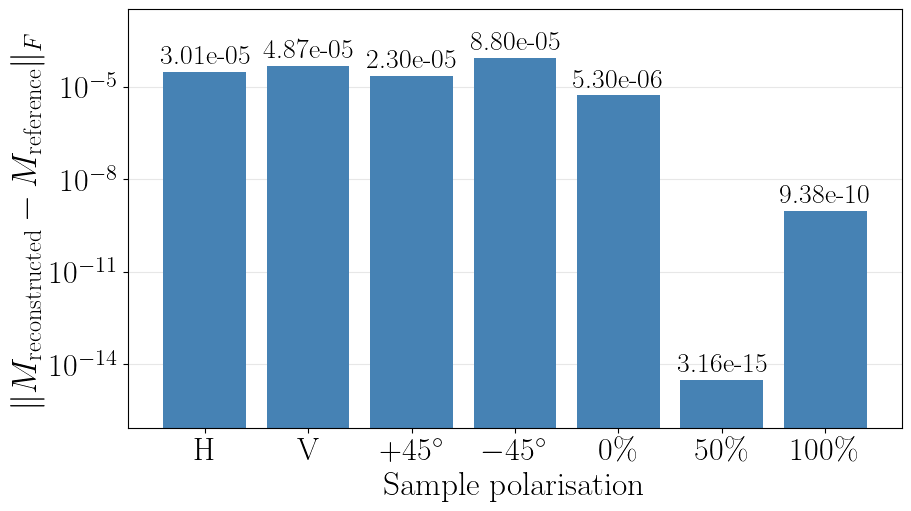

In [24]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 9,
})


case_names = [case["name"] for case in cases]
errors = np.array([
    results[name]["error_F"]
    for name in case_names
])

display_names = [
    "H",
    "V",
    r"$+45^\circ$",
    r"$-45^\circ$",
    r"$0\%$",
    r"$50\%$",
    r"$100\%$",
]

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)

positions = np.arange(len(errors))
ax.bar(positions, errors, color="steelblue")

# Log scale reveals errors spanning several orders of magnitude
ax.set_yscale("log")
ax.set_xticks(positions)
ax.set_xticklabels(display_names, fontsize=19)
ax.set_ylabel(
    r"$\|M_{\mathrm{reconstructed}}-M_{\mathrm{reference}}\|_F$",
    fontsize=25,
)
ax.set_xlabel("Sample polarisation", fontsize=24)

for position, error in zip(positions, errors):
    ax.annotate(
        f"{error:.2e}",
        (position, error),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=20,
    )
ax.tick_params(
    axis="both",
    which="major",
    labelsize=23,
    labelbottom=True,
)
ax.margins(y=0.15)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.savefig('errorrr.pdf', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

## Calculating contrast and absorption for the heatmaps

This cell runs the simulation for every sample and all six input polarisations. It uses 51 values of $p$ between 0 and 1 and cycle counts from 1 to 100. At each point,

$$
T_f=(1-p)^2,
$$

while $T_s$ and the sample orientation stay fixed for each case, and `delta` is zero. Here $p$ controls attenuation; it is not the single-pass absorption probability.

The photon starts in path 2. After propagation, the absorption probability and port contrast are calculated as

$$
P_{\mathrm{abs}}=1-P_{\mathrm{surv}},\qquad
D=\frac{P(\mathrm{ICCD0})-P(\mathrm{ICCD1})}
{P(\mathrm{ICCD0})+P(\mathrm{ICCD1})}.
$$

Positive $D$ means more surviving photons reach ICCD0; negative $D$ means more reach ICCD1. If survival is too small to calculate the ratio reliably, `D` is stored as `NaN`.

The code checks that the two detector probabilities add up to the survival probability. It saves the results in `all_heatmap_results`-- both heatmaps use these stored results, so they can be redrawn without repeating the calculation.

In [25]:
# Path projectors
P1 = np.array([[1, 0], [0, 0]], dtype=complex)
P2 = np.array([[0, 0], [0, 1]], dtype=complex)

heatmap_delta = 0.0

# Sweep Tf = (1 - p)^2; keep Ts and theta from each case
heatmap_p = np.linspace(0.0, 1.0, 51)
heatmap_n = np.arange(1, 101)

heatmap_labels = ["H", "V", "D", "A", "R", "L"]

heatmap_inputs = [
    np.kron(
        P2,
        density_from_stokes(
            conditional_input_stokes[input_label],
            enforce_normalised=True,
        ),
    )
    for input_label in heatmap_labels
]

# Store a separate set of heatmaps for every case
all_heatmap_results = {}

for case in cases:
    heatmap_Ts = case["Ts"]
    heatmap_theta = case["theta"]

    print(
        f"\nCalculating sweep: {case['name']} "
        f"(fixed Ts={heatmap_Ts:g}, "
        f"theta={np.rad2deg(heatmap_theta):g} degrees)",
        flush=True,
    )

    # Dimensions: input polarisation, cycle count, p
    heatmap_D = np.full(
        (len(heatmap_labels), len(heatmap_n), len(heatmap_p)),
        np.nan,
    )
    heatmap_absorption = np.full_like(heatmap_D, np.nan)

    for k, p_value in enumerate(heatmap_p):
        heatmap_Tf = (1.0 - p_value)**2

        for j, cycle_count in enumerate(heatmap_n):
            for i, rho_input in enumerate(heatmap_inputs):

                stokes0, stokes1, survival, _ = simulate_stokes_out(
                    which=1,
                    n_steps=int(cycle_count),
                    theta_axis=heatmap_theta,
                    Tf=heatmap_Tf,
                    Ts=heatmap_Ts,
                    delta=heatmap_delta,
                    rho_tot_in=rho_input,
                )

                prob_iccd0 = float(stokes0[0])
                prob_iccd1 = float(stokes1[0])
                total_detected = prob_iccd0 + prob_iccd1

                if not np.all(np.isfinite([
                    prob_iccd0, prob_iccd1, survival
                ])):
                    raise ValueError(
                        "Non-finite output probabilities."
                    )

                if not np.isclose(
                    total_detected,
                    survival,
                    atol=1e-10,
                    rtol=0,
                ):
                    raise ValueError(
                        "Detector probabilities do not match survival."
                    )

                heatmap_absorption[i, j, k] = 1.0 - survival

                if total_detected > 1e-12:
                    heatmap_D[i, j, k] = (
                        (prob_iccd0 - prob_iccd1)
                        / total_detected
                    )

        print(
            f"  Completed p value {k + 1}/{len(heatmap_p)}",
            flush=True,
        )

    all_heatmap_results[case["name"]] = {
        "p": heatmap_p.copy(),
        "n": heatmap_n.copy(),
        "labels": heatmap_labels.copy(),
        "Tf_values": (1.0 - heatmap_p)**2,
        "Ts": heatmap_Ts,
        "theta": heatmap_theta,
        "delta": heatmap_delta,
        "D": heatmap_D.copy(),
        "P_absorbed": heatmap_absorption.copy(),
    }


Calculating sweep: Horizontal Polariser (fixed Ts=0, theta=0 degrees)
  Completed p value 1/51
  Completed p value 2/51
  Completed p value 3/51
  Completed p value 4/51
  Completed p value 5/51
  Completed p value 6/51
  Completed p value 7/51
  Completed p value 8/51
  Completed p value 9/51
  Completed p value 10/51
  Completed p value 11/51
  Completed p value 12/51
  Completed p value 13/51
  Completed p value 14/51
  Completed p value 15/51
  Completed p value 16/51
  Completed p value 17/51
  Completed p value 18/51
  Completed p value 19/51
  Completed p value 20/51
  Completed p value 21/51
  Completed p value 22/51
  Completed p value 23/51
  Completed p value 24/51
  Completed p value 25/51
  Completed p value 26/51
  Completed p value 27/51
  Completed p value 28/51
  Completed p value 29/51
  Completed p value 30/51
  Completed p value 31/51
  Completed p value 32/51
  Completed p value 33/51
  Completed p value 34/51
  Completed p value 35/51
  Completed p value 36/51
  

## Plotting the output-port contrast

This cell plots the stored contrast $D$ against attenuation $p$ and cycle count $n$. It shows all six input polarisations for each sample. The fifth case is omitted because sweeping $T_f=(1-p)^2$ while keeping $T_s=0$ and $\theta=0$ makes it identical to the first case.

At $D=1$, all detected photons reach ICCD0; at $D=-1$, they reach ICCD1. At $D=0$, both detectors are equally likely.

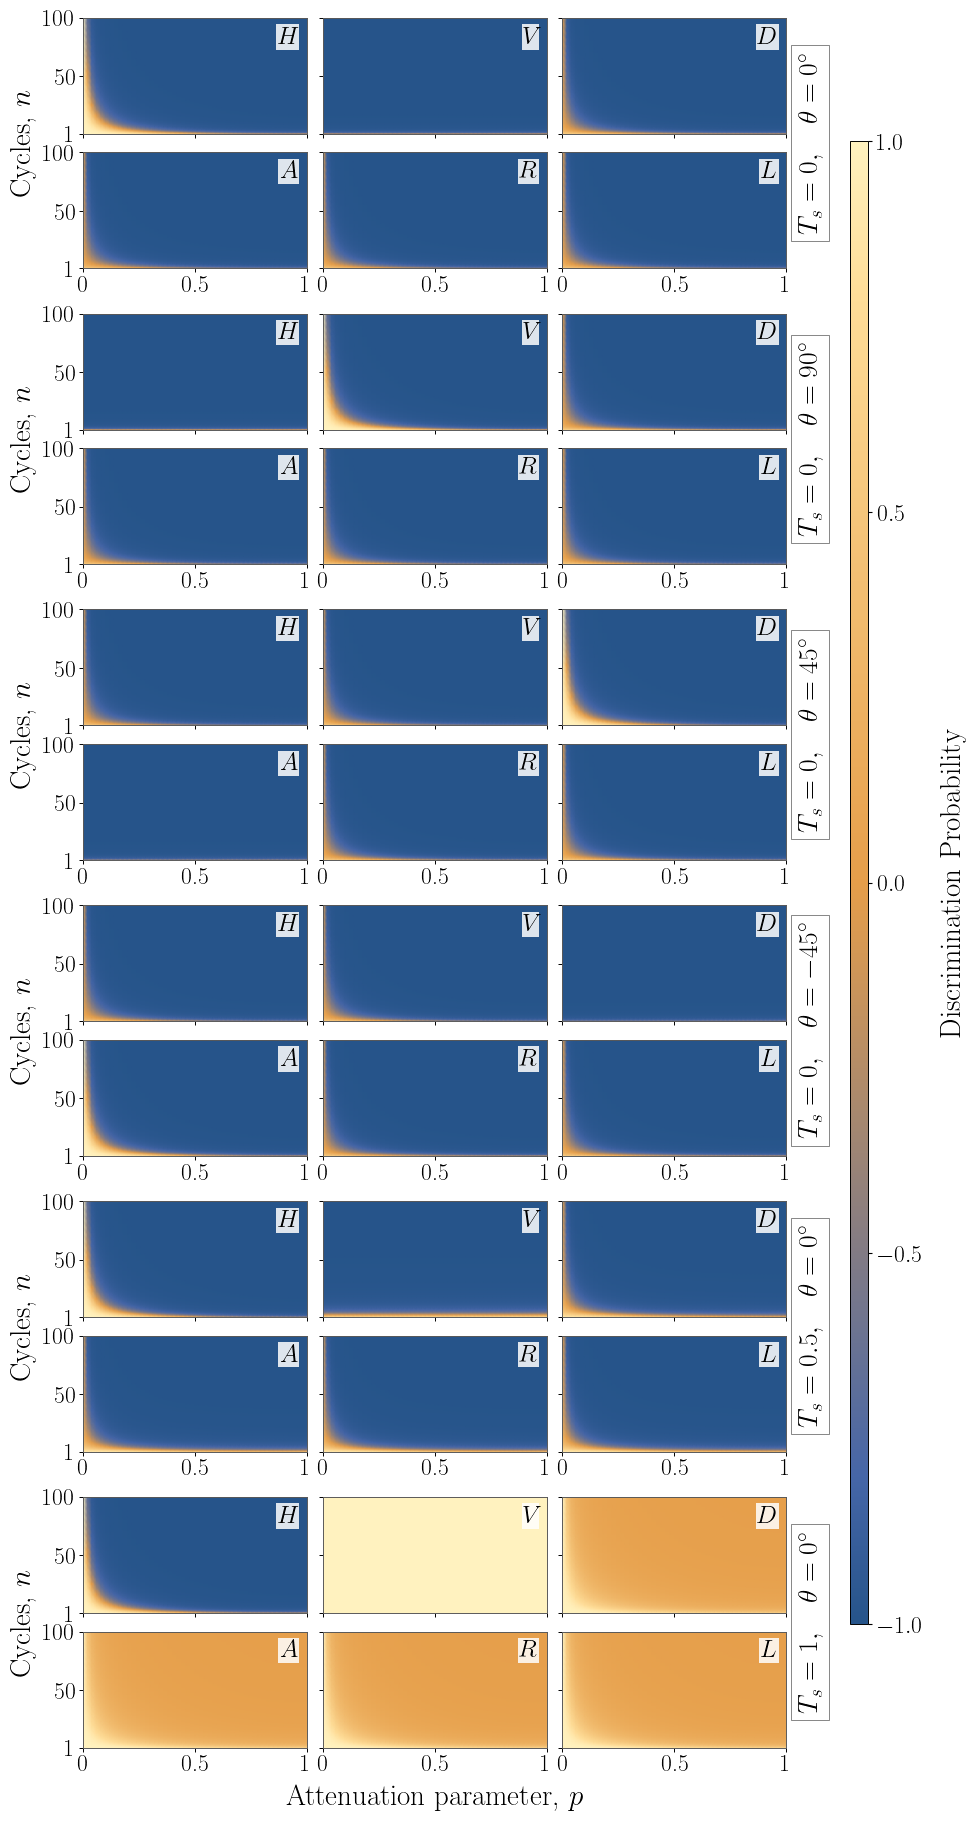

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

#creates `mathematica_cmap`, a colour gradient running from blue through orange to pale yellow. 
mathematica_cmap = LinearSegmentedColormap.from_list(
    'M10DefaultDensityGradient',
    [(0.0, (0.148, 0.330, 0.540)),
     (0.1, (0.274, 0.400, 0.658)),
     (0.5, (0.900, 0.620, 0.290)),
     (0.9, (1.000, 0.870, 0.600)),
     (1.0, (1.000, 0.950, 0.750))],
    N=2001,
)



saved_cases = list(all_heatmap_results.items())
saved_cases = [
    item
    for i, item in enumerate(all_heatmap_results.items())
    if i != 4  # Exclude the fifth case
]
number_of_cases = len(saved_cases)


with plt.rc_context({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 12,
    "axes.linewidth": 0.7,
    "xtick.direction": "out",
    "ytick.direction": "out",
}):
    fig_all = plt.figure(
        figsize=(10, 3.1 * number_of_cases),
    )

    # Dedicated columns for panels, case labels, and colourbar
    outer = fig_all.add_gridspec(
        number_of_cases, 3,
        width_ratios=[1, 0.11, 0.025],
        left=0.10,
        right=0.92,
        bottom=0.055,
        top=0.985,
        hspace=0.18,
        wspace=0.04,
    )

    for case_index, (case_name, data) in enumerate(saved_cases):
        inner = outer[case_index, 0].subgridspec(
            2, 3,
            hspace=0.16,
            wspace=0.07,
        )

        first_ax = None

        for i, input_label in enumerate(data["labels"]):
            row, col = divmod(i, 3)

            ax = fig_all.add_subplot(
                inner[row, col],
                sharex=first_ax,
                sharey=first_ax,
            )

            if first_ax is None:
                first_ax = ax

            mesh = ax.pcolormesh(
                data["p"],
                data["n"],
                data["D"][i],
                shading="gouraud",
                cmap=mathematica_cmap,
                vmin=-1,
                vmax=1,
                rasterized=True,
            )

            ax.text(
                0.96, 0.93,
                rf"${input_label}$",
                transform=ax.transAxes,
                ha="right",
                va="top",
                fontsize=18,
                bbox=dict(
                    facecolor="white",
                    alpha=0.85,
                    edgecolor="none",
                    pad=1.0,
                ),
            )

            ax.set_xlim(data["p"][0], data["p"][-1])
            ax.set_ylim(data["n"][0], data["n"][-1])

            ax.set_xticks([0, 0.5, 1])
            ax.set_xticklabels(["0", "0.5", "1"])

            ax.set_yticks(
                np.unique(
                    np.rint(
                        np.linspace(
                            data["n"][0],
                            data["n"][-1],
                            3,
                        )
                    ).astype(int)
                )
            )

            ax.tick_params(
                axis="both",
                labelsize=17,
                length=3,
                width=0.7,
                pad=2,
                labelbottom=(row == 1),
                labelleft=(col == 0),
            )

            for spine in ax.spines.values():
                spine.set_color("0.35")
                spine.set_linewidth(0.7)

        # Shared labels for each case group
        group_ax = fig_all.add_subplot(outer[case_index, 0])
        group_ax.set_axis_off()
        group_ax.patch.set_visible(False)

        '''group_ax.text(
            -0.10, 1.0,
            f"({chr(97 + case_index)})",
            transform=group_ax.transAxes,
            ha="left",
            va="top",
            fontsize=14,
            clip_on=False,
        )'''

        group_ax.text(
            -0.085, 0.5,
            r"Cycles, $n$",
            transform=group_ax.transAxes,
            rotation=90,
            ha="center",
            va="center",
            fontsize=21,
            clip_on=False,
        )

        # Only one x-axis title, below the last case
        if case_index == number_of_cases - 1:
            group_ax.text(
                0.5, -0.15,
                r"Attenuation parameter, $p$",
                transform=group_ax.transAxes,
                ha="center",
                va="top",
                fontsize=21,
                clip_on=False,
            )

        # Narrow side panel keeps text close to the heatmaps
        side_ax = fig_all.add_subplot(outer[case_index, 1])
        side_ax.set_axis_off()

        display_name = case_name.strip()
        display_name = display_name.replace(
            " degree", r"$^{\circ}$"
        )
        display_name = display_name.replace(
            r"\%", "%"
        ).replace("%", r"\%")


        parameter_text = (
            rf"$T_s={data['Ts']:g},\quad "
            rf"\theta={np.rad2deg(data['theta']):g}^\circ$"
        )

        side_ax.text(
            0.17, 0.5,
            parameter_text,
            transform=side_ax.transAxes,
            rotation=90,
            rotation_mode="anchor",
            ha="center",
            va="center",
            fontsize=20,
            linespacing=1.2,
            bbox=dict(
                boxstyle="square,pad=0.25",
                facecolor="white",
                edgecolor="0.45",
                linewidth=0.6,
            ),
        )

    # One elongated colourbar
    colour_grid = outer[:, 2].subgridspec(
        3, 1,
        height_ratios=[1, 12, 1],
        hspace=0,
    )
    colour_ax = fig_all.add_subplot(colour_grid[1, 0])
    position = colour_ax.get_position()
    colour_ax.set_position([
        position.x0 - 0.035,  # Move the whole colourbar left
        position.y0,
        position.width,
        position.height,
    ])

    colourbar = fig_all.colorbar(
        mesh,
        cax=colour_ax,
        ticks=[-1, -0.5, 0, 0.5, 1],
    )
    colourbar.ax.tick_params(labelsize=19)

    colourbar.set_label(
        r"Discrimination Probability",
        fontsize=21,
        labelpad=12,
    )
    colourbar.ax.tick_params(labelsize=17, length=3)
    colourbar.outline.set_linewidth(0.7)

    fig_all.savefig(
        "discrimination_compact.pdf",
        dpi=400,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()

## Plotting the absorption probability

This cell plots the stored absorption probabilities against attenuation $p$ and cycle count $n$. It uses the same layout as the discriminatiion figure, showing six input polarisations for each sample and omitting the duplicate fifth case. 

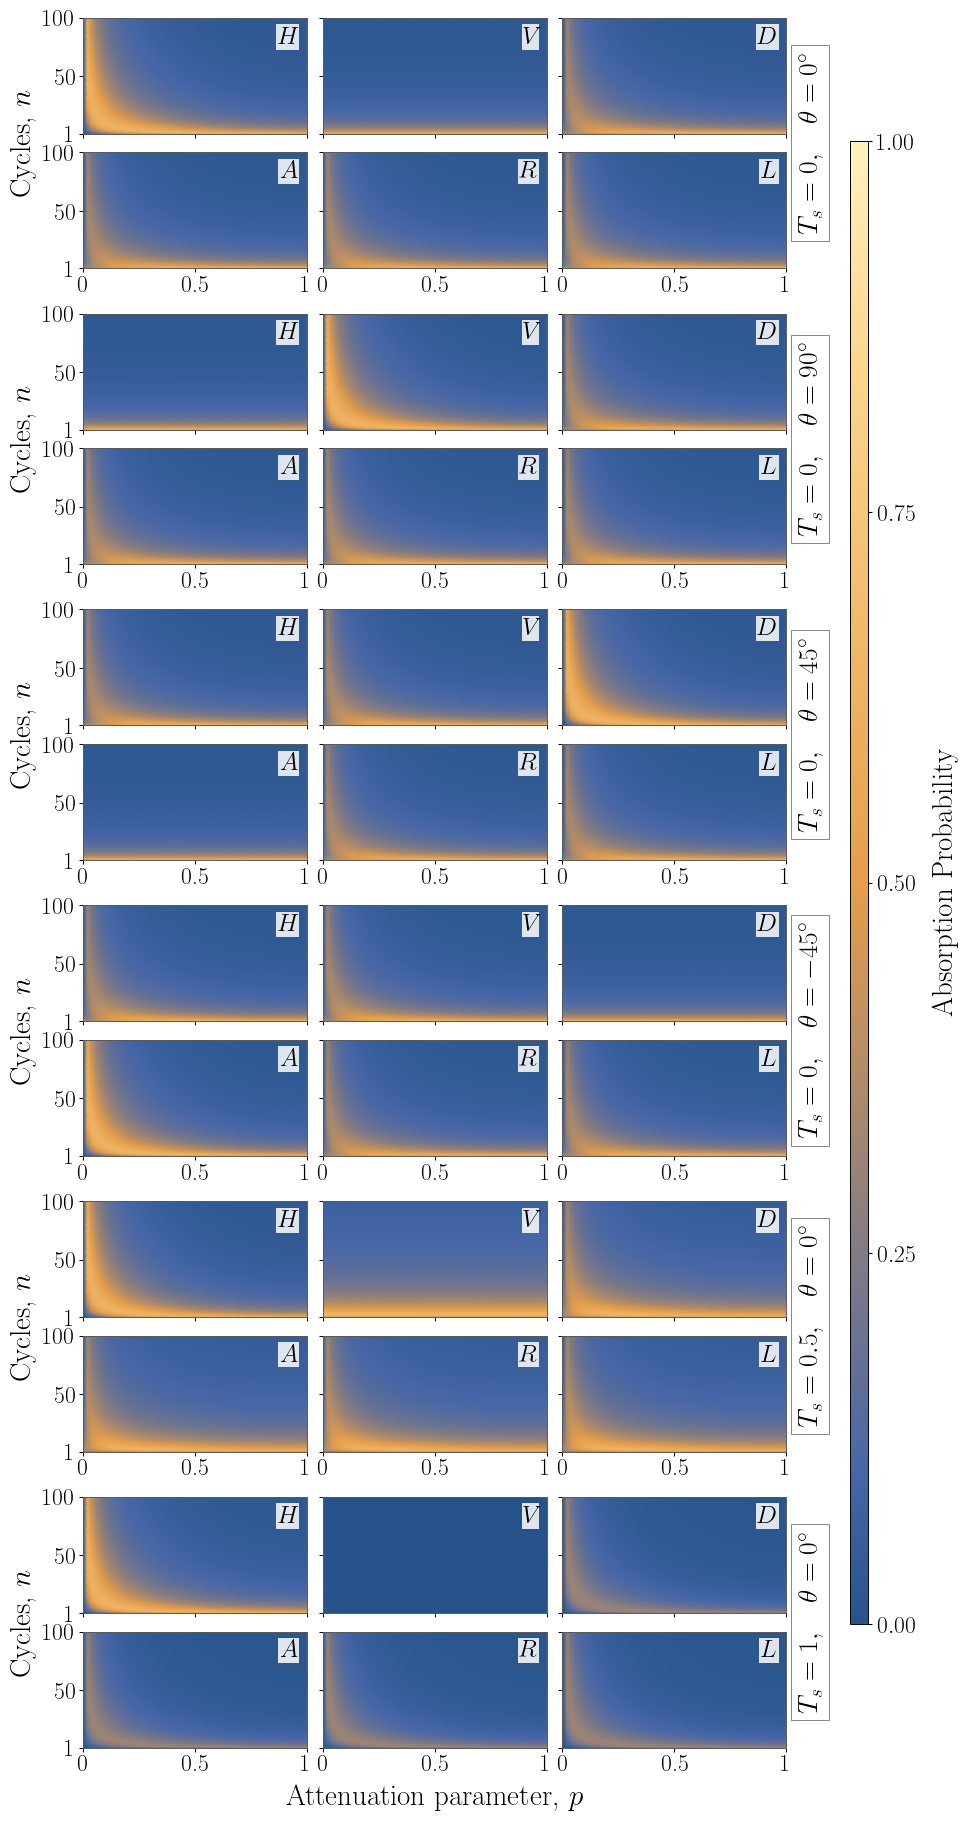

In [27]:
 import numpy as np
import matplotlib.pyplot as plt

saved_cases = list(all_heatmap_results.items())
saved_cases = [
    item
    for i, item in enumerate(all_heatmap_results.items())
    if i != 4  # Exclude the fifth case
]
number_of_cases = len(saved_cases)


with plt.rc_context({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 12,
    "axes.linewidth": 0.7,
    "xtick.direction": "out",
    "ytick.direction": "out",
}):
    fig_all = plt.figure(
        figsize=(10, 3.1 * number_of_cases),
    )

    # Dedicated columns for panels, case labels, and colourbar
    outer = fig_all.add_gridspec(
        number_of_cases, 3,
        width_ratios=[1, 0.11, 0.025],
        left=0.10,
        right=0.92,
        bottom=0.055,
        top=0.985,
        hspace=0.18,
        wspace=0.04,
    )

    for case_index, (case_name, data) in enumerate(saved_cases):
        inner = outer[case_index, 0].subgridspec(
            2, 3,
            hspace=0.16,
            wspace=0.07,
        )

        first_ax = None

        for i, input_label in enumerate(data["labels"]):
            row, col = divmod(i, 3)

            ax = fig_all.add_subplot(
                inner[row, col],
                sharex=first_ax,
                sharey=first_ax,
            )

            if first_ax is None:
                first_ax = ax

            mesh = ax.pcolormesh(
                data["p"],
                data["n"],
                # 1. Plot absorption instead of contrast
                data["P_absorbed"][i],
                shading="gouraud",
                cmap=mathematica_cmap,
                vmin=0,
                vmax=1,
                rasterized=True,
            )

            ax.text(
                0.96, 0.93,
                rf"${input_label}$",
                transform=ax.transAxes,
                ha="right",
                va="top",
                fontsize=18,
                bbox=dict(
                    facecolor="white",
                    alpha=0.85,
                    edgecolor="none",
                    pad=1.0,
                ),
            )

            ax.set_xlim(data["p"][0], data["p"][-1])
            ax.set_ylim(data["n"][0], data["n"][-1])

            ax.set_xticks([0, 0.5, 1])
            ax.set_xticklabels(["0", "0.5", "1"])

            ax.set_yticks(
                np.unique(
                    np.rint(
                        np.linspace(
                            data["n"][0],
                            data["n"][-1],
                            3,
                        )
                    ).astype(int)
                )
            )

            ax.tick_params(
                axis="both",
                labelsize=17,
                length=3,
                width=0.7,
                pad=2,
                labelbottom=(row == 1),
                labelleft=(col == 0),
            )

            for spine in ax.spines.values():
                spine.set_color("0.35")
                spine.set_linewidth(0.7)

        # Shared labels for each case group
        group_ax = fig_all.add_subplot(outer[case_index, 0])
        group_ax.set_axis_off()
        group_ax.patch.set_visible(False)

        '''group_ax.text(
            -0.10, 1.0,
            f"({chr(97 + case_index)})",
            transform=group_ax.transAxes,
            ha="left",
            va="top",
            fontsize=14,
            clip_on=False,
        )'''

        group_ax.text(
            -0.085, 0.5,
            r"Cycles, $n$",
            transform=group_ax.transAxes,
            rotation=90,
            ha="center",
            va="center",
            fontsize=21,
            clip_on=False,
        )

        # Only one x-axis title, below the last case
        if case_index == number_of_cases - 1:
            group_ax.text(
                0.5, -0.15,
                r"Attenuation parameter, $p$",
                transform=group_ax.transAxes,
                ha="center",
                va="top",
                fontsize=21,
                clip_on=False,
            )

        # Narrow side panel keeps text close to the heatmaps
        side_ax = fig_all.add_subplot(outer[case_index, 1])
        side_ax.set_axis_off()

        display_name = case_name.strip()
        display_name = display_name.replace(
            " degree", r"$^{\circ}$"
        )
        display_name = display_name.replace(
            r"\%", "%"
        ).replace("%", r"\%")


        parameter_text = (
            rf"$T_s={data['Ts']:g},\quad "
            rf"\theta={np.rad2deg(data['theta']):g}^\circ$"
        )

        side_ax.text(
            0.17, 0.5,
            parameter_text,
            transform=side_ax.transAxes,
            rotation=90,
            rotation_mode="anchor",
            ha="center",
            va="center",
            fontsize=20,
            linespacing=1.2,
            bbox=dict(
                boxstyle="square,pad=0.25",
                facecolor="white",
                edgecolor="0.45",
                linewidth=0.6,
            ),
        )

    # One elongated colourbar
    colour_grid = outer[:, 2].subgridspec(
        3, 1,
        height_ratios=[1, 12, 1],
        hspace=0,
    )
    colour_ax = fig_all.add_subplot(colour_grid[1, 0])
    position = colour_ax.get_position()
    colour_ax.set_position([
        position.x0 - 0.035,  # Move the whole colourbar left
        position.y0,
        position.width,
        position.height,
    ])

    colourbar = fig_all.colorbar(
        mesh,
        cax=colour_ax,
        # 3. Replace the colourbar ticks
        ticks=[0, 0.25, 0.5, 0.75, 1],
    )
    colourbar.ax.tick_params(labelsize=19)

    colourbar.set_label(
        # 4. Replace the colourbar label
    r"Absorption Probability",
        fontsize=21,
        labelpad=12,
    )
    colourbar.ax.tick_params(labelsize=17, length=3)
    colourbar.outline.set_linewidth(0.7)

    fig_all.savefig(
        # 5. Save under a different filename
"absorption_compact.pdf",
        dpi=400,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()

## Calculate SNR from the absent and present signals

We now simulates the empty interferometer for every input and cycle count. We then simulates each sample and compares the two detector probabilities with that reference.

Let $p_0^{\mathrm{absent}}$ and $p_1^{\mathrm{absent}}$ be the reference port probabilities, and let $p_0^{\mathrm{present}}$ and $p_1^{\mathrm{present}}$ be the sample-present probabilities. The stored SNR coefficient is

$$
s=\frac{\left|(p_0^{\mathrm{absent}}-p_1^{\mathrm{absent}})
-(p_0^{\mathrm{present}}-p_1^{\mathrm{present}})\right|}
{\sqrt{p_0^{\mathrm{absent}}+p_1^{\mathrm{absent}}
+p_0^{\mathrm{present}}+p_1^{\mathrm{present}}}}.
$$

The numerator measures the change in detector imbalance. The denominator follows from adding the variances of four independent Poisson detector counts. With the same mean incident count $N$ in each of the absent and present measurements, the SNR is $\sqrt{N}\,s$. Thus the stored value is SNR divided by $\sqrt{N}$ ($N$ is the mean number of incident photons in each measurement).


In [28]:
import numpy as np
import matplotlib.pyplot as plt

snr_n_values = np.arange(1, 101)
snr_input_labels = ["H", "V", "D", "A", "R", "L"]
snr_path2 = np.array([[0, 0], [0, 1]], dtype=complex)

snr_rho_inputs = [
    np.kron(
        snr_path2,
        density_from_stokes(
            conditional_input_stokes[input_label],
            enforce_normalised=True,
        ),
    )
    for input_label in snr_input_labels
]

# Recalculate the no-object reference outputs once for each input and n.
snr_absent_P0 = np.zeros((len(snr_input_labels), len(snr_n_values)))
snr_absent_P1 = np.zeros_like(snr_absent_P0)

print("Fresh simulation: object absent (which=0)", flush=True)
for n_index, cycle_count in enumerate(snr_n_values):
    for input_index, rho_input in enumerate(snr_rho_inputs):
        stokes0, stokes1, survival, _ = simulate_stokes_out(
            which=0,
            n_steps=int(cycle_count),
            theta_axis=0.0,
            Tf=1.0,
            Ts=1.0,
            delta=0.0,
            rho_tot_in=rho_input,
        )

        probability0 = float(stokes0[0])
        probability1 = float(stokes1[0])

        if not np.isclose(
            probability0 + probability1,
            survival,
            atol=1e-10,
            rtol=0,
        ):
            raise ValueError(
                f"Absent-object detector probabilities do not sum to "
                f"survival for n={cycle_count}, "
                f"input={snr_input_labels[input_index]}."
            )

        snr_absent_P0[input_index, n_index] = probability0
        snr_absent_P1[input_index, n_index] = probability1

snr_results = {}

# For each case, compare that sample-present simulation with the absent baseline.
for snr_case in cases:
    print(f"Fresh simulation: object present: {snr_case['name']}", flush=True)

    snr_present_P0 = np.zeros_like(snr_absent_P0)
    snr_present_P1 = np.zeros_like(snr_absent_P1)

    for n_index, cycle_count in enumerate(snr_n_values):
        for input_index, rho_input in enumerate(snr_rho_inputs):
            stokes0, stokes1, survival, _ = simulate_stokes_out(
                which=1,
                n_steps=int(cycle_count),
                theta_axis=snr_case["theta"],
                Tf=snr_case["Tf"],
                Ts=snr_case["Ts"],
                delta=0.0,
                rho_tot_in=rho_input,
            )

            probability0 = float(stokes0[0])
            probability1 = float(stokes1[0])

            if not np.isclose(
                probability0 + probability1,
                survival,
                atol=1e-10,
                rtol=0,
            ):
                raise ValueError(
                    f"Present-object detector probabilities do not sum to "
                    f"survival for {snr_case['name']}, n={cycle_count}, "
                    f"input={snr_input_labels[input_index]}."
                )

            snr_present_P0[input_index, n_index] = probability0
            snr_present_P1[input_index, n_index] = probability1

    # Changes in each detector probability: absent minus present.
    delta_P0 = snr_absent_P0 - snr_present_P0
    delta_P1 = snr_absent_P1 - snr_present_P1

    # Signal is the change in the detector difference (ICCD0 minus ICCD1).
    snr_signal_per_photon = np.abs(delta_P0 - delta_P1)

    # Poisson variance from both detectors under both hypotheses.
    snr_variance_per_photon = (
        snr_absent_P0 + snr_absent_P1
        + snr_present_P0 + snr_present_P1
    )

    snr_per_sqrt_incident_photon = np.divide(
        snr_signal_per_photon,
        np.sqrt(snr_variance_per_photon),
        out=np.full_like(snr_signal_per_photon, np.nan),
        where=snr_variance_per_photon > 1e-15,
    )

    snr_results[snr_case["name"]] = {
        "n": snr_n_values.copy(),
        "labels": snr_input_labels.copy(),
        "P_iccd0_absent": snr_absent_P0.copy(),
        "P_iccd1_absent": snr_absent_P1.copy(),
        "P_iccd0_present": snr_present_P0.copy(),
        "P_iccd1_present": snr_present_P1.copy(),
        "snr_per_sqrt_incident_photon":
            snr_per_sqrt_incident_photon.copy(),
    }



Fresh simulation: object absent (which=0)
Fresh simulation: object present: Horizontal Polariser
Fresh simulation: object present: Vertical Polariser
Fresh simulation: object present: +45$^{\circ}$ Polariser
Fresh simulation: object present: -45$^{\circ}$ Polariser
Fresh simulation: object present: 0% Transmission
Fresh simulation: object present: 50% Transmission
Fresh simulation: object present: 100% Transmission


## Plot SNR and SNR normalised by absorption

This cell creates a two-column figure. Each row is one sample, and the six curves correspond to H, V, D, A, R and L inputs. The horizontal axis is the number of cycles.

The left column plots the coefficient $s=\mathrm{SNR}/\sqrt{N}$ calculated above. The right column plots

$$
\frac{s}{\sqrt{P_{\mathrm{abs}}}}
=\frac{\mathrm{SNR}}{\sqrt{N_{\mathrm{abs}}}},
\qquad N_{\mathrm{abs}}=N P_{\mathrm{abs}}.
$$

Here $N_{\mathrm{abs}}$ is the expected number absorbed in the sample-present measurement. The absent reference is lossless. To obtain SNR for a chosen budget, multiply the left coefficient by $\sqrt{N}$ or the right coefficient by $\sqrt{N_{\mathrm{abs}}}$.

TThe code normalises by the square root of the absorbed count. It leaves values undefined (NaN) where $P_{\mathrm{abs}}\leq10^{-12}$, so zero-absorption inputs do not produce curves in the right column.

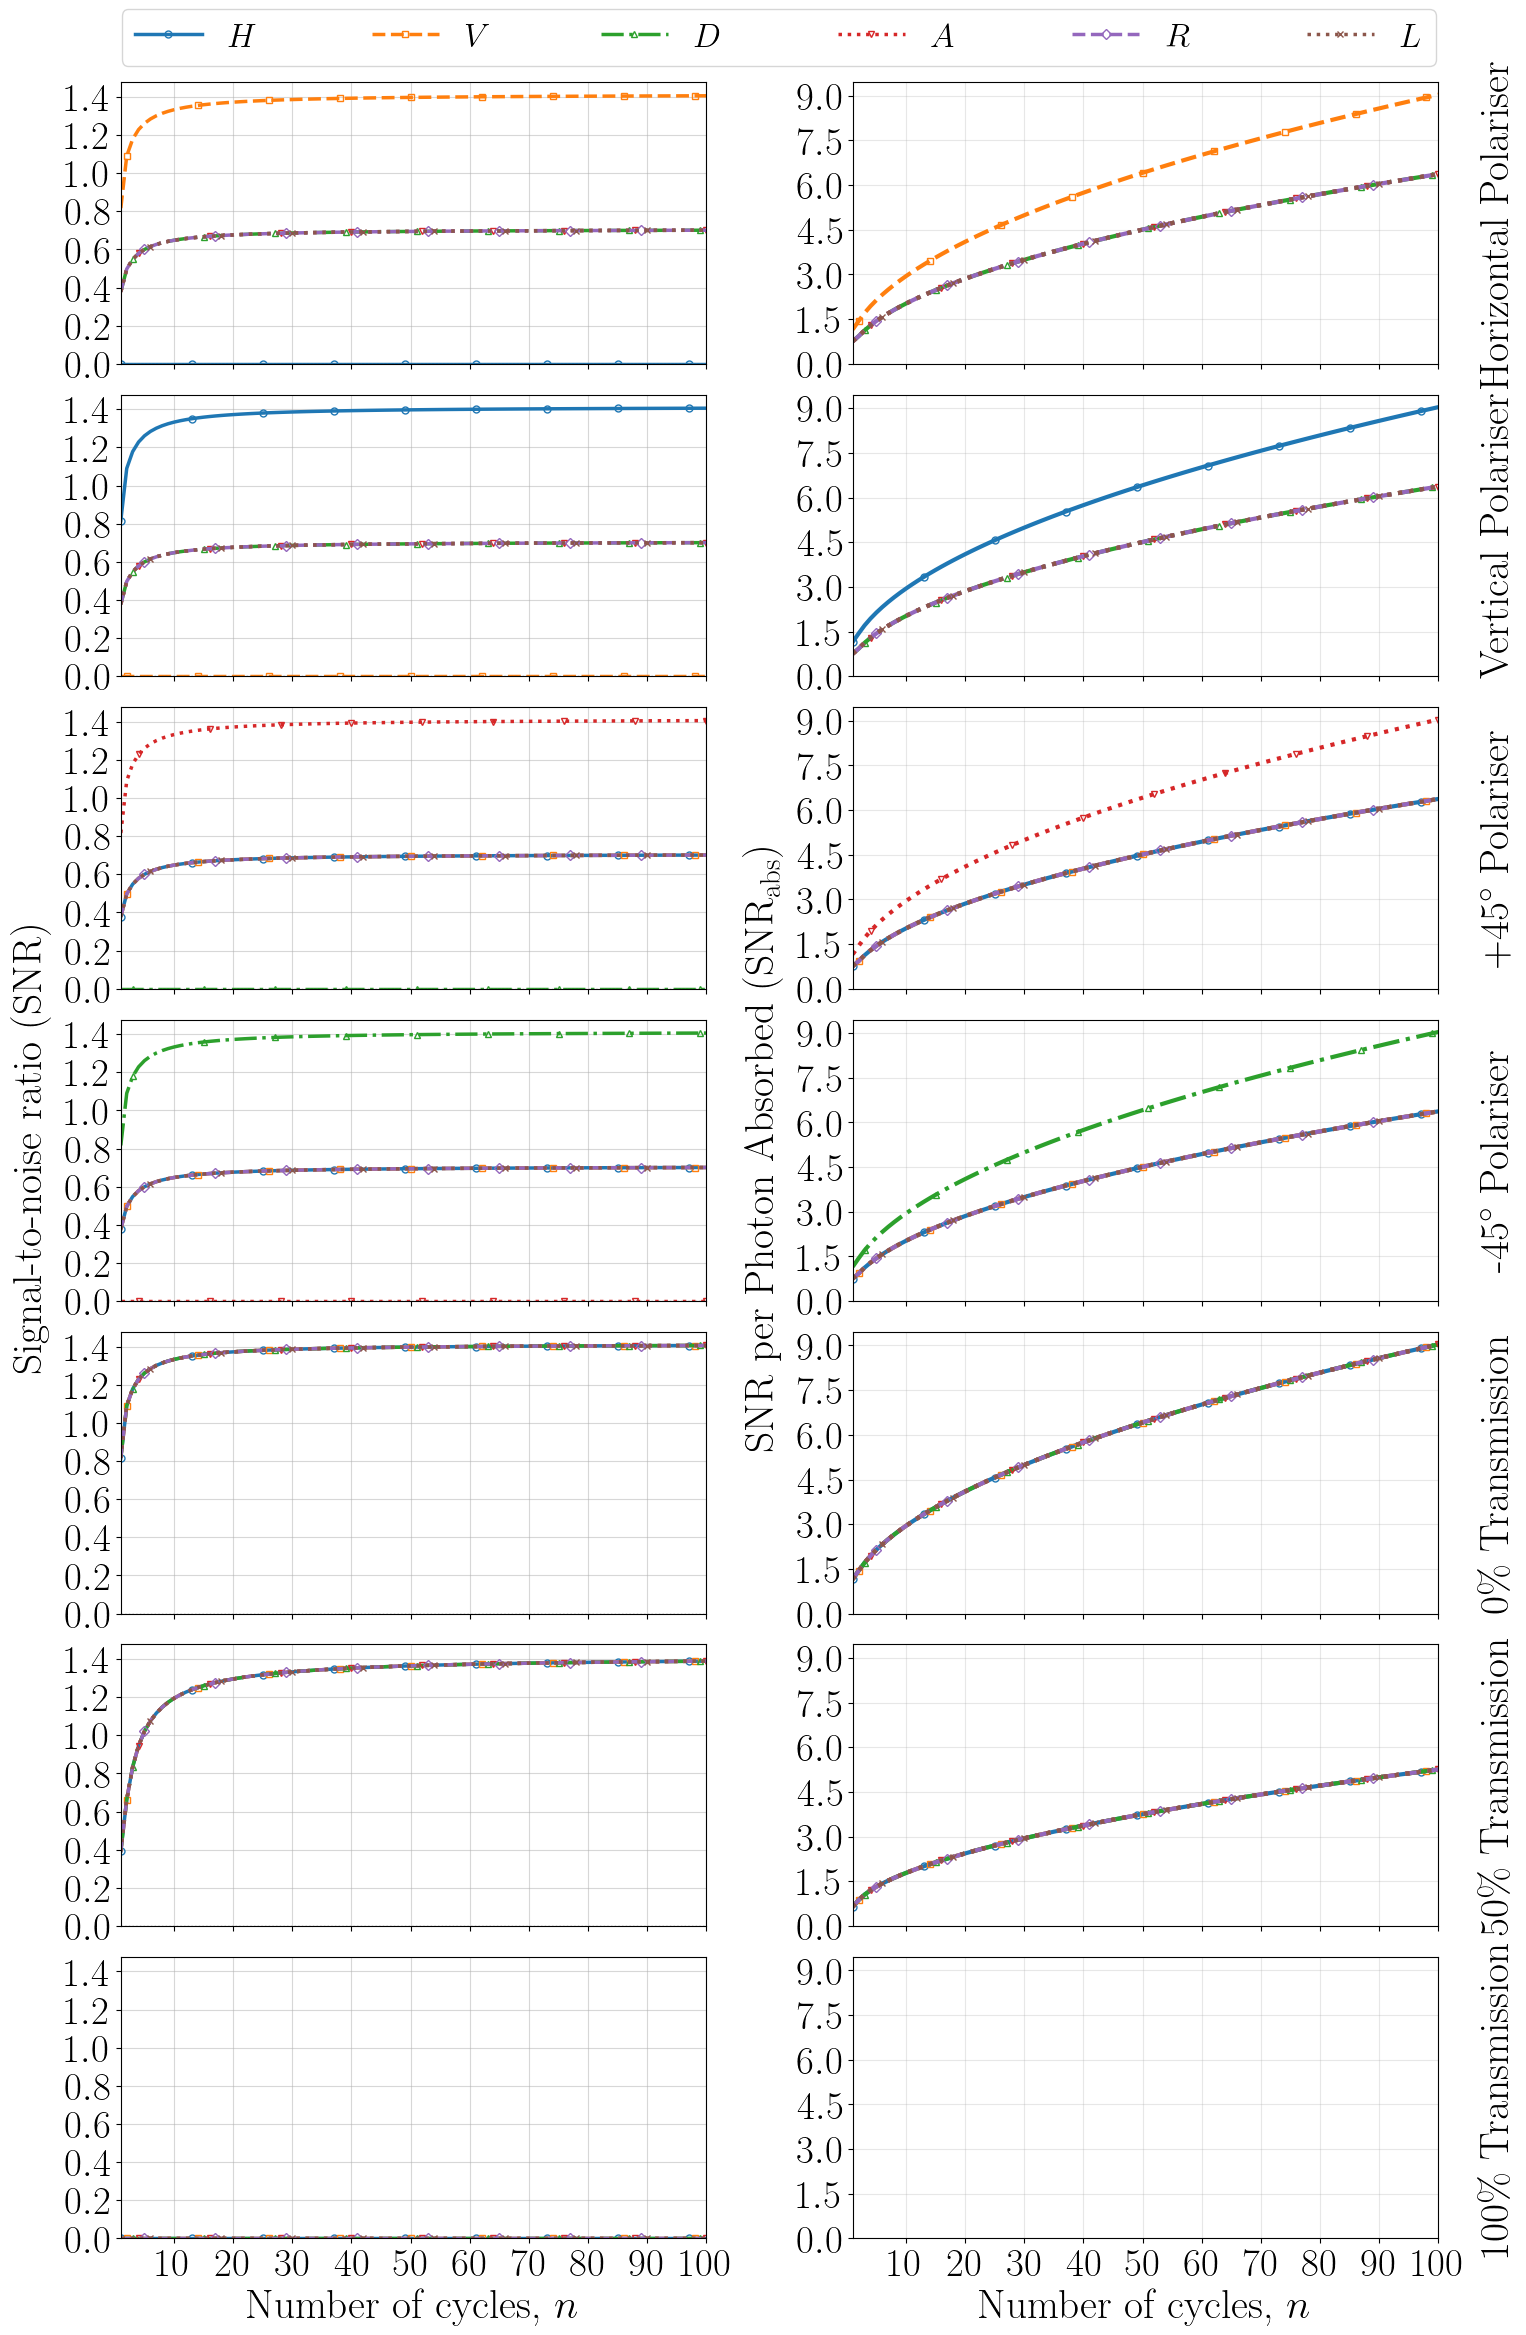

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 9,
})



fig_SNR, axes_SNR = plt.subplots(
    nrows=len(cases),
    ncols=2,
    figsize=(17, 4 * len(cases)),
    sharex=True,
    sharey="col",
    squeeze=False,
    constrained_layout=False,
)

fig_SNR.subplots_adjust(wspace=0.25, hspace=0.11)

styles_SNR = ["-", "--", "-.", ":", "--", ":"]
markers_SNR = ["o", "s", "^", "v", "D", "x"]

for row, sample_case in enumerate(cases):
    ax_left = axes_SNR[row, 0]
    ax_right = axes_SNR[row, 1]

    data_SNR = snr_results[sample_case["name"]]
    data_abs = absorption_results[sample_case["name"]]

    P_absorbed = np.asarray(
        data_abs["P_absorbed"],
        dtype=float,
    )

    for i, input_label in enumerate(data_SNR["labels"]):
        sample_snr_values = np.asarray(
            data_SNR["snr_per_sqrt_incident_photon"][i],
            dtype=float,
        )

        snr_per_absorption = np.divide(
            sample_snr_values,
            np.sqrt(np.clip(P_absorbed[i], 0.0, None)),
            out=np.full_like(sample_snr_values, np.nan),
            where=P_absorbed[i] > 1e-12,
        )

        # Left: ordinary SNR.
        ax_left.plot(
            data_SNR["n"],
            sample_snr_values,
            label=rf"${input_label}$",
            linewidth=2.5,
            linestyle=styles_SNR[i % len(styles_SNR)],
            marker=markers_SNR[i % len(markers_SNR)],
            markersize=5,
            markerfacecolor="none",
            markevery=(i, 12),
        )

        # Right: absorption-normalised SNR.
        ax_right.plot(
            data_SNR["n"],
            snr_per_absorption,
            label=rf"${input_label}$",
            linewidth=3,
            linestyle=styles_SNR[i % len(styles_SNR)],
            marker=markers_SNR[i % len(markers_SNR)],
            markersize=5,
            markerfacecolor="none",
            markevery=(i, 12),
        )

    case_name = sample_case["name"].strip()
    case_name = case_name.replace(" degree", r"$^{\circ}$")
    case_name = case_name.replace(r"\%", "%").replace("%", r"\%")

    for col, ax_SNR in enumerate([ax_left, ax_right]):
        
        if col == 1:
            ax_SNR.text(
                1.07, 0.5,
                case_name,
                transform=ax_SNR.transAxes,
                rotation=90,
                va="center",
                ha="left",
                fontsize=30,
                clip_on=False,
            )

        ax_SNR.set_ylim(bottom=0)
        ax_SNR.set_xlim(
            snr_n_values[0],
            snr_n_values[-1],
        )

        ax_SNR.tick_params(axis="both", labelsize=28)
        ax_SNR.tick_params(
            axis="x",
            labelbottom=(row == len(cases) - 1),
        )

        ax_SNR.yaxis.set_major_locator(MaxNLocator(nbins=8))
        ax_SNR.xaxis.set_major_locator(MaxNLocator(nbins=10))
        ax_SNR.set_axisbelow(True)

        ax_SNR.grid(
            True,
            axis="both",
            alpha=0.5 if col == 0 else 0.3,
        )

    ax_left.axhline(
        0,
        color="grey",
        linestyle=":",
        linewidth=1,
    )

# One shared legend above both columns.
handles, labels = axes_SNR[0, 0].get_legend_handles_labels()

fig_SNR.legend(
    handles,
    labels,
    ncol=6,
    loc="lower center",
    bbox_to_anchor=(0.512, 0.88),
    fontsize=24,
    columnspacing=3.5,
)
'''# Legends above both columns.
for ax_SNR in axes_SNR[0, :]:
    ax_SNR.legend(
        ncol=6,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.98),
        fontsize=24,
        columnspacing=0.63,
    )'''

# Bottom x-axis labels.
for ax_SNR in axes_SNR[-1, :]:
    ax_SNR.set_xlabel(
        r"Number of cycles, $n$",
        fontsize=30,
    )

# Column labels positioned beside the entire grid,
# avoiding long labels on individual middle panels.
fig_SNR.canvas.draw()

left_position = axes_SNR[0, 0].get_position()
right_position = axes_SNR[0, 1].get_position()

fig_SNR.text(
    left_position.x0 - 0.053,
    0.5,
    r"Signal-to-noise ratio (SNR)",
    rotation=90,
    va="center",
    ha="center",
    fontsize=30,
)

fig_SNR.text(
    right_position.x0 - 0.053,
    0.5,
    r"SNR per Photon Absorbed ($\mathrm{SNR}_{\mathrm{abs}}$)",
    rotation=90,
    va="center",
    ha="center",
    fontsize=30,
)

fig_SNR.savefig(
    "snr_side_by_side.pdf",
    bbox_inches="tight",
    transparent=True,
)

plt.show()

## Results at 100 cycles

This cell displays the absorption probability, $\mathrm{SNR}/\sqrt{N}$ and $\mathrm{SNR}/\sqrt{N_{\mathrm{abs}}}$ for all seven samples and six input polarisations at $n=100$. Values with effectively zero absorption show `NaN` in the last column. The table is stored as `values_at_100` and displayed to six decimal places.

In [32]:
import pandas as pd

rows = []

for sample_case in cases:
    name = sample_case["name"]
    data_SNR = snr_results[name]
    data_abs = absorption_results[name]

    snr_index = np.flatnonzero(np.asarray(data_SNR["n"]) == 100)[0]
    abs_index = np.flatnonzero(np.asarray(data_abs["n"]) == 100)[0]

    for i, input_label in enumerate(data_SNR["labels"]):
        abs_i = list(data_abs["labels"]).index(input_label)

        snr_value = float(
            data_SNR["snr_per_sqrt_incident_photon"][i][snr_index]
        )
        absorption = float(
            data_abs["P_absorbed"][abs_i][abs_index]
        )

        absorbed_snr = (
            snr_value / np.sqrt(absorption)
            if absorption > 1e-12 else np.nan
        )

        rows.append({
            "Sample": name,
            "Input": input_label,
            "n": 100,
            "P_absorbed": absorption,
            "SNR / sqrt(N)": snr_value,
            "SNR / sqrt(N_abs)": absorbed_snr,
        })

values_at_100 = pd.DataFrame(rows)

with pd.option_context("display.max_rows", None):
    display(values_at_100.round(6))

,Sample,Input,n,P_absorbed,SNR / sqrt(N),SNR / sqrt(N_abs)
0,Horizontal Polariser,H,100,0.000000,0.000000,NaN
1,Horizontal Polariser,V,100,0.024193,1.405549,9.036606
2,Horizontal Polariser,D,100,0.012096,0.700633,6.370375
3,Horizontal Polariser,A,100,0.012096,0.700633,6.370375
4,Horizontal Polariser,R,100,0.012096,0.700633,6.370375
5,Horizontal Polariser,L,100,0.012096,0.700633,6.370375
6,Vertical Polariser,H,100,0.024193,1.405549,9.036606
7,Vertical Polariser,V,100,0.000000,0.000000,NaN
8,Vertical Polariser,D,100,0.012096,0.700633,6.370375
9,Vertical Polariser,A,100,0.012096,0.700633,6.370375


## Export the horizontal-polariser and opaque-sample table at 100 cycles

This cell selects the horizontal ideal polariser ($T_f=1$, $T_s=0$, $\theta=0$) and the opaque sample ($T_f=T_s=0$). It extracts their six input-polarisation results at $n=100$.

Absorption values within $10^{-12}$ of zero are set to zero for reporting. The absorption-normalised SNR is left undefined in those cases. 


In [33]:
import numpy as np
import pandas as pd

selected_cases = [
    case for case in cases
    if (
        np.isclose(case["theta"], 0.0)
        and np.isclose(case["Tf"], 1.0)
        and np.isclose(case["Ts"], 0.0)
    ) or (
        np.isclose(case["Tf"], 0.0)
        and np.isclose(case["Ts"], 0.0)
    )
]

rows = []

for sample_case in selected_cases:
    name = sample_case["name"]
    data_SNR = snr_results[name]
    data_abs = absorption_results[name]

    snr_index = np.flatnonzero(
        np.asarray(data_SNR["n"]) == 100
    )[0]
    abs_index = np.flatnonzero(
        np.asarray(data_abs["n"]) == 100
    )[0]

    for i, input_label in enumerate(data_SNR["labels"]):
        abs_i = list(data_abs["labels"]).index(input_label)

        snr_value = float(
            data_SNR["snr_per_sqrt_incident_photon"][i][snr_index]
        )
        absorption = float(
            data_abs["P_absorbed"][abs_i][abs_index]
        )

        if abs(absorption) <= 1e-12:
            absorption = 0.0

        absorbed_snr = (
            snr_value / np.sqrt(absorption)
            if absorption > 1e-12 else np.nan
        )

        rows.append({
            "Sample": name,
            "Input": input_label,
            "n": 100,
            "P_absorbed": absorption,
            "SNR / sqrt(N)": snr_value,
            "SNR / sqrt(N_abs)": absorbed_snr,
        })

values_at_100 = pd.DataFrame(rows)

with pd.option_context("display.max_rows", None):
    display(values_at_100.round(6))



latex_table = values_at_100.to_latex(
    index=False,
    float_format="%.6f",
    na_rep="---",
    caption="Results at $n=100$ for a horizontal polariser and 0% transmission.",
    label="tab:snr_horizontal_opaque",
    escape=True,
)

print(latex_table)

with open("snr_horizontal_opaque.tex", "w") as file:
    file.write(latex_table)

,Sample,Input,n,P_absorbed,SNR / sqrt(N),SNR / sqrt(N_abs)
0,Horizontal Polariser,H,100,0.000000,0.000000,NaN
1,Horizontal Polariser,V,100,0.024193,1.405549,9.036606
2,Horizontal Polariser,D,100,0.012096,0.700633,6.370375
3,Horizontal Polariser,A,100,0.012096,0.700633,6.370375
4,Horizontal Polariser,R,100,0.012096,0.700633,6.370375
5,Horizontal Polariser,L,100,0.012096,0.700633,6.370375
6,0% Transmission,H,100,0.024193,1.405549,9.036606
7,0% Transmission,V,100,0.024193,1.405549,9.036606
8,0% Transmission,D,100,0.024193,1.405549,9.036606
9,0% Transmission,A,100,0.024193,1.405549,9.036606


\begin{table}
\caption{Results at $n=100$ for a horizontal polariser and 0% transmission.}
\label{tab:snr_horizontal_opaque}
\begin{tabular}{llrrrr}
\toprule
Sample & Input & n & P\_absorbed & SNR / sqrt(N) & SNR / sqrt(N\_abs) \\
\midrule
Horizontal Polariser & H & 100 & 0.000000 & 0.000000 & --- \\
Horizontal Polariser & V & 100 & 0.024193 & 1.405549 & 9.036606 \\
Horizontal Polariser & D & 100 & 0.012096 & 0.700633 & 6.370375 \\
Horizontal Polariser & A & 100 & 0.012096 & 0.700633 & 6.370375 \\
Horizontal Polariser & R & 100 & 0.012096 & 0.700633 & 6.370375 \\
Horizontal Polariser & L & 100 & 0.012096 & 0.700633 & 6.370375 \\
0\% Transmission & H & 100 & 0.024193 & 1.405549 & 9.036606 \\
0\% Transmission & V & 100 & 0.024193 & 1.405549 & 9.036606 \\
0\% Transmission & D & 100 & 0.024193 & 1.405549 & 9.036606 \\
0\% Transmission & A & 100 & 0.024193 & 1.405549 & 9.036606 \\
0\% Transmission & R & 100 & 0.024193 & 1.405549 & 9.036606 \\
0\% Transmission & L & 100 & 0.024193 & 1.405549

## Export the same two samples at one cycle

This cell repeats the selected-sample table for `target_n=1`, using the previously calculated arrays.

In [36]:

import numpy as np
import pandas as pd

target_n = 1

# Select horizontal polariser and 0% transmission.
selected_cases = [
    case for case in cases
    if (
        np.isclose(case["theta"], 0.0)
        and np.isclose(case["Tf"], 1.0)
        and np.isclose(case["Ts"], 0.0)
    ) or (
        np.isclose(case["Tf"], 0.0)
        and np.isclose(case["Ts"], 0.0)
    )
]

rows = []

for sample_case in selected_cases:
    name = sample_case["name"]
    data_SNR = snr_results[name]
    data_abs = absorption_results[name]

    snr_index = np.flatnonzero(
        np.asarray(data_SNR["n"]) == target_n
    )[0]
    abs_index = np.flatnonzero(
        np.asarray(data_abs["n"]) == target_n
    )[0]

    for i, input_label in enumerate(data_SNR["labels"]):
        abs_i = list(data_abs["labels"]).index(input_label)

        snr_value = float(
            data_SNR["snr_per_sqrt_incident_photon"][i][snr_index]
        )
        absorption = float(
            data_abs["P_absorbed"][abs_i][abs_index]
        )

        # Remove tiny numerical roundoff around zero.
        if abs(absorption) <= 1e-12:
            absorption = 0.0

        absorbed_snr = (
            snr_value / np.sqrt(absorption)
            if absorption > 1e-12 else np.nan
        )

        rows.append({
            "Sample": name,
            "Input": input_label,
            "n": target_n,
            "P_absorbed": absorption,
            "SNR / sqrt(N)": snr_value,
            "SNR / sqrt(N_abs)": absorbed_snr,
        })

values_at_1 = pd.DataFrame(rows)

with pd.option_context("display.max_rows", None):
    display(values_at_1.round(6))

# Generate the LaTeX table.
latex_table = values_at_1.to_latex(
    index=False,
    float_format="%.6f",
    na_rep="---",
    caption=(
        r"Results at $n=1$ for a horizontal polariser "
        r"and 0\% transmission. One cycle contains two sample passes."
    ),
    label="tab:snr_horizontal_opaque_n1",
    escape=True,
)

print(latex_table)

with open("snr_horizontal_opaque_n1.tex", "w") as file:
    file.write(latex_table)

,Sample,Input,n,P_absorbed,SNR / sqrt(N),SNR / sqrt(N_abs)
0,Horizontal Polariser,H,1,0.00,0.000000,NaN
1,Horizontal Polariser,V,1,0.50,0.816497,1.154701
2,Horizontal Polariser,D,1,0.25,0.377964,0.755929
3,Horizontal Polariser,A,1,0.25,0.377964,0.755929
4,Horizontal Polariser,R,1,0.25,0.377964,0.755929
5,Horizontal Polariser,L,1,0.25,0.377964,0.755929
6,0% Transmission,H,1,0.50,0.816497,1.154701
7,0% Transmission,V,1,0.50,0.816497,1.154701
8,0% Transmission,D,1,0.50,0.816497,1.154701
9,0% Transmission,A,1,0.50,0.816497,1.154701


\begin{table}
\caption{Results at $n=1$ for a horizontal polariser and 0\% transmission. One cycle contains two sample passes.}
\label{tab:snr_horizontal_opaque_n1}
\begin{tabular}{llrrrr}
\toprule
Sample & Input & n & P\_absorbed & SNR / sqrt(N) & SNR / sqrt(N\_abs) \\
\midrule
Horizontal Polariser & H & 1 & 0.000000 & 0.000000 & --- \\
Horizontal Polariser & V & 1 & 0.500000 & 0.816497 & 1.154701 \\
Horizontal Polariser & D & 1 & 0.250000 & 0.377964 & 0.755929 \\
Horizontal Polariser & A & 1 & 0.250000 & 0.377964 & 0.755929 \\
Horizontal Polariser & R & 1 & 0.250000 & 0.377964 & 0.755929 \\
Horizontal Polariser & L & 1 & 0.250000 & 0.377964 & 0.755929 \\
0\% Transmission & H & 1 & 0.500000 & 0.816497 & 1.154701 \\
0\% Transmission & V & 1 & 0.500000 & 0.816497 & 1.154701 \\
0\% Transmission & D & 1 & 0.500000 & 0.816497 & 1.154701 \\
0\% Transmission & A & 1 & 0.500000 & 0.816497 & 1.154701 \\
0\% Transmission & R & 1 & 0.500000 & 0.816497 & 1.154701 \\
0\% Transmission & L & 1 & 0.5

# ------------------------------- THE END -----------------------------------